In [1]:
import os, math, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp
import torch
from torch import nn

# Make Colab CPU and local runs reproducible and inexpensive.
torch.set_num_threads(min(4, max(1, os.cpu_count() or 1)))
DEVICE = torch.device('cpu')
DTYPE = torch.float32
SIGMAS = np.array([0.20, 0.75, 2.00], dtype=np.float32)
POLICIES = ['uniform_K16', 'adaptive_ESS', 'shuffled_ESS', 'uniform_K12_plus_pilot']


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


def log_normal(x, mean, log_std):
    return -0.5 * ((x-mean)/torch.exp(log_std))**2 - log_std - 0.5*np.log(2*np.pi)


def generate_data(n, seed):
    rng=np.random.default_rng(seed)
    c=np.arange(n,dtype=np.int64)%len(SIGMAS)
    rng.shuffle(c)
    z=rng.normal(size=n).astype('float32')
    x=(z+SIGMAS[c]*rng.normal(size=n)).astype('float32')
    return torch.tensor(x),torch.tensor(c)


def exact_posterior(x, c):
    sigma=torch.as_tensor(SIGMAS, dtype=x.dtype,device=x.device)[c]
    v=(sigma**2)/(1+sigma**2)
    m=x/(1+sigma**2)
    return m, torch.sqrt(v)


def log_joint(z,x,c):
    sigma=torch.as_tensor(SIGMAS,dtype=x.dtype,device=x.device)[c]
    return log_normal(z,torch.zeros_like(z),torch.zeros_like(z))+log_normal(x,z,torch.log(sigma))


def exact_log_evidence(x,c):
    sigma=torch.as_tensor(SIGMAS,dtype=x.dtype,device=x.device)[c]
    return log_normal(x,torch.zeros_like(x),0.5*torch.log1p(sigma**2))


class AmortizedGaussian(nn.Module):
    def __init__(self,width=32):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(4,width),nn.Tanh(),nn.Linear(width,width),nn.Tanh(),nn.Linear(width,2))
        with torch.no_grad():
            nn.init.zeros_(self.net[-1].weight)
            nn.init.zeros_(self.net[-1].bias)
    def forward(self,x,c):
        features=torch.cat((x[:,None],torch.nn.functional.one_hot(c,3).float()),dim=1)
        out=self.net(features)
        return out[:,0],torch.clamp(out[:,1],-2.5,0.8)


def posterior_metrics(model,x,c):
    model.eval()
    with torch.no_grad():
        mu,ls=model(x,c)
        pm,ps=exact_posterior(x,c)
        qv=torch.exp(2*ls); pv=ps**2
        # KL(p || q) and KL(q || p) for Gaussian p, q
        kl_pq=0.5*(torch.log(qv/pv)+(pv+(pm-mu)**2)/qv-1)
        kl_qp=0.5*(torch.log(pv/qv)+(qv+(pm-mu)**2)/pv-1)
        e=(mu-pm)**2
        rows=[]
        for ctx in range(3):
            mask=(c==ctx)
            rows.append({'context':ctx,'n':int(mask.sum()),'forward_KL':float(kl_pq[mask].mean()),'reverse_KL':float(kl_qp[mask].mean()),'mean_rmse':float(torch.sqrt(e[mask].mean()))})
        rows.append({'context':'ALL','n':len(x),'forward_KL':float(kl_pq.mean()),'reverse_KL':float(kl_qp.mean()),'mean_rmse':float(torch.sqrt(e.mean()))})
    return pd.DataFrame(rows)


def pilot_complexity(model,x,c,K0=4):
    with torch.no_grad():
        mu,ls=model(x,c); B=len(x)
        z=mu[:,None]+torch.exp(ls)[:,None]*torch.randn(B,K0)
        logw=log_joint(z,x[:,None],c[:,None])-log_normal(z,mu[:,None],ls[:,None])
        logess=2*torch.logsumexp(logw,dim=1)-torch.logsumexp(2*logw,dim=1)
        ess=torch.exp(logess).clamp(1,K0)
        cv2=(K0/ess-1).clamp_min(0)
        return (cv2+0.05).sqrt().cpu().numpy(),ess.cpu().numpy()


def capped_allocate(scores,total,min_k=4,max_k=64):
    scores=np.asarray(scores,dtype=float); B=len(scores)
    assert min_k*B <= total <= max_k*B
    extra=total-B*min_k
    if extra==0: return np.full(B,min_k,dtype=int)
    weights=np.maximum(scores,1e-6)
    # Continuous capped water filling, then largest-remainder integerization.
    lo,hi=0.,max(1.,float(extra)/weights.min())
    for _ in range(45):
        mid=(lo+hi)/2
        if np.minimum(max_k-min_k,mid*weights).sum() < extra: lo=mid
        else: hi=mid
    continuous=np.minimum(max_k-min_k,hi*weights)
    alloc=np.floor(continuous).astype(int)
    remain=int(extra-alloc.sum())
    if remain>0:
        frac=continuous-alloc
        valid=alloc<(max_k-min_k)
        order=np.argsort(-np.where(valid,frac,-np.inf),kind='stable')
        alloc[order[:remain]]+=1
    elif remain<0:
        order=np.argsort(continuous-alloc,kind='stable')
        alloc[order[:(-remain)]]-=1
    out=alloc+min_k
    assert out.sum()==total and out.min()>=min_k and out.max()<=max_k,(out.sum(),total,out.min(),out.max())
    return out


def get_allocation(model,x,c,policy,avg_K=16,K0=4):
    B=len(x)
    if policy=='uniform_K16':
        return np.full(B,avg_K,dtype=int),0,np.nan
    complexity, ess=pilot_complexity(model,x,c,K0)
    if policy=='uniform_K12_plus_pilot':
        return np.full(B,avg_K-K0,dtype=int),B*K0,float(np.mean(ess/K0))
    # All methods using a pilot spend B*K0 model likelihood evaluations.
    allocated=capped_allocate(complexity,total=B*(avg_K-K0),min_k=4,max_k=64)
    if policy=='shuffled_ESS':
        allocated=np.random.permutation(allocated)
    return allocated,B*K0,float(np.mean(ess/K0))


def rws_update(model,opt,x,c,counts):
    # Independent (fresh) proposal samples are drawn after pilot-based allocation.
    # RWS / inclusive KL gradient estimate using self-normalized importance weights.
    # The generated z and normalized weights are detached: neither IWAE DReG nor
    # naive gradient of the IWAE objective is silently claimed here.
    mu,ls=model(x,c)
    indices=torch.repeat_interleave(torch.arange(len(x)),torch.as_tensor(counts))
    with torch.no_grad():
        z=mu.detach()[indices]+ls.detach()[indices].exp()*torch.randn(len(indices))
        logw=log_joint(z,x[indices],c[indices])-log_normal(z,mu.detach()[indices],ls.detach()[indices])
        max_each=torch.full((len(x),),-torch.inf,dtype=logw.dtype)
        max_each.scatter_reduce_(0,indices,logw,reduce='amax',include_self=True)
        ws=torch.exp(logw-max_each[indices])
        denom=torch.zeros(len(x)).scatter_add_(0,indices,ws)
        normalized=ws/denom[indices]
    loss=-(normalized*log_normal(z,mu[indices],ls[indices])).sum()/len(x)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(),3.0)
    opt.step()
    return float(loss.item())


def train_one(policy,seed,x_train,c_train,x_test,c_test,steps=180,batch_size=64,avg_K=16,lr=0.006,eval_every=15):
    seed_everything(seed)
    model=AmortizedGaussian()
    opt=torch.optim.Adam(model.parameters(),lr=lr)
    rng=np.random.default_rng(seed+983)
    history=[]; allocation_rows=[]
    cost=0
    metric=posterior_metrics(model,x_test,c_test)
    history.append({'policy':policy,'seed':seed,'step':0,'evaluations':0,**metric[metric.context=='ALL'].iloc[0].to_dict()})
    for step in range(1,steps+1):
        batch_ids=torch.tensor(rng.integers(0,len(x_train),size=batch_size),dtype=torch.long)
        x=x_train[batch_ids];c=c_train[batch_ids]
        counts,pilot_evals,ess=get_allocation(model,x,c,policy,avg_K=avg_K)
        model.train()
        rws_update(model,opt,x,c,counts)
        evaluations=pilot_evals+int(counts.sum())
        assert evaluations==batch_size*avg_K
        cost+=evaluations
        if step%eval_every==0 or step==steps:
            metric=posterior_metrics(model,x_test,c_test)
            history.append({'policy':policy,'seed':seed,'step':step,'evaluations':cost,**metric[metric.context=='ALL'].iloc[0].to_dict()})
        if step%20==0:
            allocation_rows.append({'policy':policy,'seed':seed,'step':step,'mean_Ktrain':float(np.mean(counts)),
                                    'min_Ktrain':int(np.min(counts)),'max_Ktrain':int(np.max(counts)),
                                    'pilot_mean_ESS_ratio':ess})
    return model,pd.DataFrame(history),pd.DataFrame(allocation_rows)


def run_training_experiment(seeds=(11,29,47,83,101),steps=180,n_train=4500,n_test=1200):
    x_train,c_train=generate_data(n_train,37)
    x_test,c_test=generate_data(n_test,53)
    histories=[]; allocations=[]; trained={}
    for seed in seeds:
        for policy in POLICIES:
            model,h,a=train_one(policy,seed,x_train,c_train,x_test,c_test,steps=steps)
            histories.append(h);allocations.append(a)
            trained[(seed,policy)]=model
            ending=h.iloc[-1]
            print(f'seed {seed:>3}  {policy:<23}  KL(p||q) {ending.forward_KL:.4f}  cost {int(ending.evaluations):,}')
    return (pd.concat(histories,ignore_index=True),pd.concat(allocations,ignore_index=True),trained,(x_train,c_train,x_test,c_test))



In [2]:
seed_everything(2022)
x_test_s, c_test_s = generate_data(9, 2021)
pm, ps = exact_posterior(x_test_s, c_test_s)
z = pm + ps * torch.randn_like(pm)
log_q_exact = log_normal(z, pm, torch.log(ps))
log_w_exact = log_joint(z, x_test_s, c_test_s) - log_q_exact
assert torch.allclose(log_w_exact, exact_log_evidence(x_test_s, c_test_s), atol=2e-5)

# Closed-form ELBO check with deliberately misspecified Gaussian proposal.
qmu, qstd = torch.zeros_like(pm), torch.ones_like(pm)
kl_qp = 0.5*(torch.log(ps**2/qstd**2) + (qstd**2+(qmu-pm)**2)/(ps**2)-1)
elbo_exact = exact_log_evidence(x_test_s,c_test_s) - kl_qp
assert torch.all(elbo_exact <= exact_log_evidence(x_test_s,c_test_s)+1e-7)
print('PASS: exact posterior, Bayes identity, and ELBO gap = reverse KL.')

PASS: exact posterior, Bayes identity, and ELBO gap = reverse KL.


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Experiment: 512
Saving results to: /content/drive/MyDrive/Adaptive_VI_Research/dev_K_512/20261119_184240_969906
Exact log evidence: -1.174126
  K  log_bound  log_bound_SE  evidence_bias  evidence_variance  log_bias
  1  -18.23856       0.42116       -0.00885            0.33197  17.06443
  2   -6.98336       0.17448        0.00062            0.17367   5.80924
  4   -2.92880       0.06800       -0.00855            0.08495   1.75467
  8   -1.58716       0.02320        0.00499            0.04262   0.41303
 16   -1.32818       0.01111       -0.00133            0.02069   0.15405
 32   -1.22696       0.00601        0.00167            0.01030   0.05284
 64   -1.20587       0.00417       -0.00079            0.00527   0.03174
128   -1.18690       0.00287        0.00045            0.00269   0.01277
256   -1.18291       0.00203       -0.00050            0.00135   0.00878

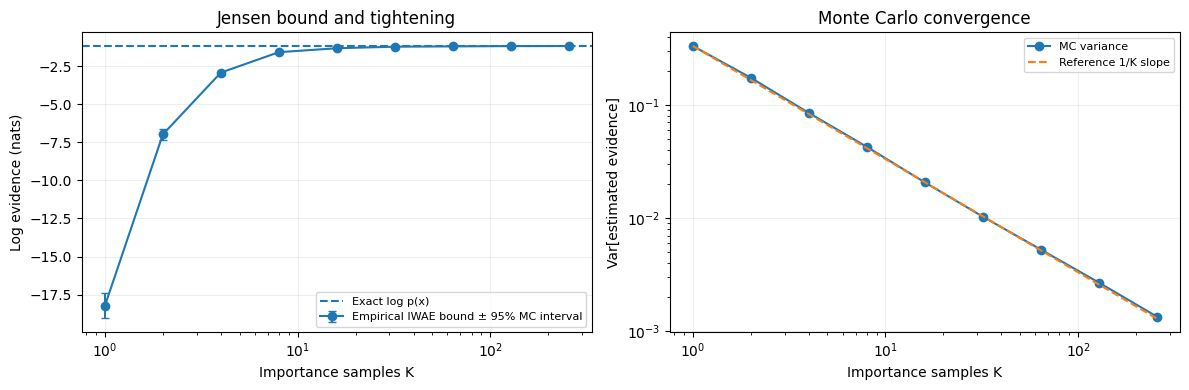

In [4]:
from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone
import json

# Connect Google Drive
drive.mount('/content/drive')

# CHANGE ONLY THIS PARAMETER FOR EACH EXPERIMENT
DEV_K = 512

# Unique timestamp for every execution
RUN_ID = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f"
)

# Separate directory for each parameter and run
ROOT_DIR = Path(
    "/content/drive/MyDrive/Adaptive_VI_Research"
)

OUT_DIR = ROOT_DIR / f"dev_K_{DEV_K}" / RUN_ID
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Experiment:", DEV_K)
print("Saving results to:", OUT_DIR)


# Fixed hard observation in the most informative context; q(z|x,c) = p(z).
# Then w = p(x|z,c), allowing vectorized independent Monte Carlo replications.
rng_mc = np.random.default_rng(802)
fixed_x, fixed_c = 0.7, 0
sigma = float(SIGMAS[fixed_c])
true_Z = float(np.exp(-0.5*fixed_x**2/(1+sigma**2)) / np.sqrt(2*np.pi*(1+sigma**2)))
K_grid = [1, 2, 4, 8, 16, 32, 64, 128, 256]
R = 3500
mc_rows=[]
for K in K_grid:
    draw_z = rng_mc.normal(size=(R,K))
    logw = -0.5*((fixed_x-draw_z)/sigma)**2 - np.log(sigma*np.sqrt(2*np.pi))
    logZ_hat = logsumexp(logw, axis=1) - np.log(K)
    Z_hat = np.exp(logZ_hat)
    mc_rows.append({'K':K, 'log_bound':logZ_hat.mean(),
                    'log_bound_SE':logZ_hat.std(ddof=1)/np.sqrt(R),
                    'evidence_bias':Z_hat.mean()-true_Z,
                    'evidence_variance':Z_hat.var(ddof=1),
                    'log_bias':np.log(true_Z)-logZ_hat.mean()})
mc_df=pd.DataFrame(mc_rows)
print('Exact log evidence:',round(np.log(true_Z),6))
print(mc_df.round(5).to_string(index=False))
assert np.all(mc_df['log_bias'] > -0.035)  # 3,500-repetition MC tolerance

fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].errorbar(mc_df.K,mc_df.log_bound,yerr=1.96*mc_df.log_bound_SE,fmt='o-',capsize=3,label='Empirical IWAE bound ± 95% MC interval')
ax[0].axhline(np.log(true_Z),ls='--',label='Exact log p(x)')
ax[0].set(xscale='log',xlabel='Importance samples K',ylabel='Log evidence (nats)',title='Jensen bound and tightening')
ax[0].legend(fontsize=8); ax[0].grid(alpha=.2)
ax[1].loglog(mc_df.K,mc_df.evidence_variance,'o-',label='MC variance')
ax[1].loglog(mc_df.K,mc_df.evidence_variance.iloc[0]/mc_df.K,'--',label='Reference 1/K slope')
ax[1].set(xlabel='Importance samples K',ylabel='Var[estimated evidence]',title='Monte Carlo convergence')
ax[1].legend(fontsize=8); ax[1].grid(alpha=.2)
fig.tight_layout();fig.savefig(OUT_DIR/'01_jensen_mc_convergence.png',dpi=170);plt.show()
mc_df.to_csv(OUT_DIR/'mc_convergence.csv',index=False)

In [5]:
def estimate_posterior_means(model,x,c,policy,avg_K=24,K0=6):
    # Draw pilot samples solely to decide allocation; they are charged but NOT
    # included in final IS estimates, preventing reuse/optional stopping bias.
    B=len(x)
    if policy=='uniform_K24':
        counts=np.full(B,avg_K,dtype=int)
        pilot_cost=0
    elif policy=='uniform_K18_plus_pilot':
        scores,ess=pilot_complexity(model,x,c,K0=K0)
        counts=np.full(B,avg_K-K0,dtype=int)
        pilot_cost=B*K0
    else:
        scores,ess=pilot_complexity(model,x,c,K0=K0)
        counts=capped_allocate(scores,total=B*(avg_K-K0),min_k=4,max_k=100)
        if policy=='shuffled_ESS': counts=np.random.permutation(counts)
        pilot_cost=B*K0
    assert int(counts.sum())+pilot_cost==B*avg_K
    with torch.no_grad():
        mu,ls=model(x,c)
        indices=torch.repeat_interleave(torch.arange(B),torch.as_tensor(counts))
        z=mu[indices]+torch.exp(ls[indices])*torch.randn(len(indices))
        lw=log_joint(z,x[indices],c[indices])-log_normal(z,mu[indices],ls[indices])
        row_max=torch.full((B,),-torch.inf)
        row_max.scatter_reduce_(0,indices,lw,reduce='amax',include_self=True)
        w=torch.exp(lw-row_max[indices])
        sums=torch.zeros(B).scatter_add_(0,indices,w)
        est=torch.zeros(B).scatter_add_(0,indices,z*w)/sums
        ref,_=exact_posterior(x,c)
        err=(est-ref)**2
    return err.numpy(),counts


def run_moment_experiment(trained_model=None,replicates=100,N=240,avg_K=24,K0=6):
    seed_everything(552)
    x,c=generate_data(N,812)
    if trained_model is None:
        model=AmortizedGaussian()
    else: model=trained_model
    rows=[]
    for rep in range(replicates):
        for method in ['uniform_K24','adaptive_ESS','shuffled_ESS','uniform_K18_plus_pilot']:
            err,counts=estimate_posterior_means(model,x,c,method,avg_K=avg_K,K0=K0)
            for ctx in range(3):
                mask=c.numpy()==ctx
                rows.append({'replicate':rep,'method':method,'context':ctx,'MSE':float(err[mask].mean()),'MAEproxy':float(np.sqrt(err[mask]).mean()),'Ktrain':float(counts[mask].mean())})
            rows.append({'replicate':rep,'method':method,'context':'ALL','MSE':float(err.mean()),'MAEproxy':float(np.sqrt(err).mean()),'Ktrain':float(counts.mean())})
    return pd.DataFrame(rows)


def estimate_log_evidence(model,x,c,policy,avg_K=24,K0=6):
    B=len(x)
    if policy=='uniform_K24':
        counts=np.full(B,avg_K,dtype=int); pilot_cost=0
    else:
        scores,ess=pilot_complexity(model,x,c,K0=K0)
        pilot_cost=B*K0
        if policy=='uniform_K18_plus_pilot': counts=np.full(B,avg_K-K0,dtype=int)
        else:
            counts=capped_allocate(scores,total=B*(avg_K-K0),min_k=4,max_k=100)
            if policy=='shuffled_ESS': counts=np.random.permutation(counts)
    with torch.no_grad():
        mu,ls=model(x,c)
        idx=torch.repeat_interleave(torch.arange(B),torch.as_tensor(counts))
        z=mu[idx]+ls[idx].exp()*torch.randn(len(idx))
        lw=log_joint(z,x[idx],c[idx])-log_normal(z,mu[idx],ls[idx])
        maxes=torch.full((B,),-torch.inf);maxes.scatter_reduce_(0,idx,lw,reduce='amax',include_self=True)
        exps=torch.exp(lw-maxes[idx]);sums=torch.zeros(B).scatter_add_(0,idx,exps)
        est=maxes+torch.log(sums)-torch.log(torch.as_tensor(counts,dtype=torch.float))
        truth=exact_log_evidence(x,c)
        err=truth-est
    return err.numpy(),counts

def run_evidence_experiment(trained_model=None,replicates=100,N=240,avg_K=24,K0=6):
    seed_everything(552)
    x,c=generate_data(N,812)
    model=AmortizedGaussian() if trained_model is None else trained_model
    rows=[]
    for rep in range(replicates):
        for method in ['uniform_K24','adaptive_ESS','shuffled_ESS','uniform_K18_plus_pilot']:
            err,counts=estimate_log_evidence(model,x,c,method,avg_K=avg_K,K0=K0)
            for ctx in [0,1,2,'ALL']:
                mask=np.ones(N,dtype=bool) if ctx=='ALL' else c.numpy()==ctx
                rows.append({'replicate':rep,'method':method,'context':ctx,'gap':float(err[mask].mean()),'MAE':float(np.abs(err[mask]).mean()),'MSE':float(np.mean(err[mask]**2)),'Ktrain':float(counts[mask].mean())})
    return pd.DataFrame(rows)




Mean log evidence gaps (nats, lower is better):
                           mean      std
method                                  
adaptive_ESS            0.08663  0.03681
shuffled_ESS            0.23944  0.07737
uniform_K18_plus_pilot  0.15355  0.05787
uniform_K24             0.10603  0.04077

Posterior mean squared error (lower is better):
                           mean      std
method                                  
adaptive_ESS            0.05604  0.00608
shuffled_ESS            0.06546  0.00817
uniform_K18_plus_pilot  0.04810  0.00688
uniform_K24             0.03457  0.00521
Adaptive - uniform, gap: -0.01940; paired bootstrap 95% CI [-0.02763, -0.01071]
Adaptive - uniform, MSE: +0.02147; paired bootstrap 95% CI [+0.02028, +0.02265]


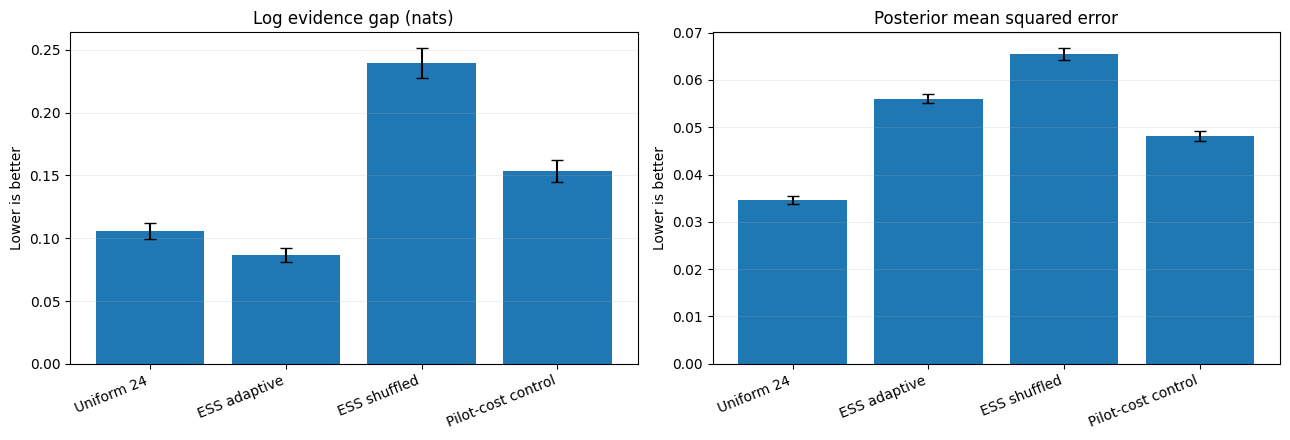


Allocated FINAL samples per context; add 6 pilot samples per observation:
          mean  median  min  max
context                         
0        28.14    28.5   13   35
1        15.72    15.0    8   35
2        10.14     9.0    7   29


In [6]:
evidence_df = run_evidence_experiment(trained_model=None, replicates=160, N=300)
moment_df = run_moment_experiment(trained_model=None, replicates=160, N=300)

def paired_bootstrap(df,metric,method,baseline,replications=5000,seed=3):
    pivot=df[df.context=='ALL'].pivot(index='replicate',columns='method',values=metric)
    diffs=(pivot[method]-pivot[baseline]).to_numpy()
    rng=np.random.default_rng(seed)
    samples=rng.choice(diffs,size=(replications,len(diffs)),replace=True).mean(axis=1)
    return float(diffs.mean()),np.quantile(samples,[.025,.975])

print('Mean log evidence gaps (nats, lower is better):')
print(evidence_df[evidence_df.context=='ALL'].groupby('method')['gap'].agg(['mean','std']).round(5))
print('\nPosterior mean squared error (lower is better):')
print(moment_df[moment_df.context=='ALL'].groupby('method')['MSE'].agg(['mean','std']).round(5))
for metric,frame in [('gap',evidence_df),('MSE',moment_df)]:
    delta,ci=paired_bootstrap(frame,metric,'adaptive_ESS','uniform_K24')
    print(f'Adaptive - uniform, {metric}: {delta:+.5f}; paired bootstrap 95% CI [{ci[0]:+.5f}, {ci[1]:+.5f}]')

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
methods=['uniform_K24','adaptive_ESS','shuffled_ESS','uniform_K18_plus_pilot']
labels=['Uniform 24','ESS adaptive','ESS shuffled','Pilot-cost control']
for ax,frame,metric,title in [(axes[0],evidence_df,'gap','Log evidence gap (nats)'),(axes[1],moment_df,'MSE','Posterior mean squared error')]:
    group=frame[frame.context=='ALL'].groupby('method')[metric]
    means=np.array([group.mean()[m] for m in methods]);
    errors=np.array([1.96*group.std()[m]/np.sqrt(group.count()[m]) for m in methods])
    ax.bar(np.arange(4),means,yerr=errors,capsize=4)
    ax.set_xticks(np.arange(4),labels,rotation=22,ha='right')
    ax.set(title=title,ylabel='Lower is better');ax.grid(axis='y',alpha=.2)
fig.tight_layout();fig.savefig(OUT_DIR/'02_allocation_tradeoff.png',dpi=170);plt.show()

# Useful diagnostic: K allocations by true observation context (synthetic test metadata).
seed_everything(992)
context_x,context_c=generate_data(600,991)
initial_model=AmortizedGaussian()
counts,pilot_cost,pilotess=get_allocation(initial_model,context_x,context_c,'adaptive_ESS',avg_K=24,K0=6)
ctx_allocation=pd.DataFrame({'context':context_c.numpy(),'training_K':counts})
print('\nAllocated FINAL samples per context; add 6 pilot samples per observation:')
print(ctx_allocation.groupby('context')['training_K'].agg(['mean','median','min','max']).round(2))
assert counts.sum()+pilot_cost==24*len(context_x)

seed  11  uniform_K16              KL(p||q) 0.0177  cost 184,320
seed  11  adaptive_ESS             KL(p||q) 0.0275  cost 184,320
seed  11  shuffled_ESS             KL(p||q) 0.0290  cost 184,320
seed  11  uniform_K12_plus_pilot   KL(p||q) 0.0315  cost 184,320
seed  29  uniform_K16              KL(p||q) 0.0145  cost 184,320
seed  29  adaptive_ESS             KL(p||q) 0.0127  cost 184,320
seed  29  shuffled_ESS             KL(p||q) 0.0238  cost 184,320
seed  29  uniform_K12_plus_pilot   KL(p||q) 0.0300  cost 184,320
seed  47  uniform_K16              KL(p||q) 0.0194  cost 184,320
seed  47  adaptive_ESS             KL(p||q) 0.0217  cost 184,320
seed  47  shuffled_ESS             KL(p||q) 0.0391  cost 184,320
seed  47  uniform_K12_plus_pilot   KL(p||q) 0.0149  cost 184,320
seed  83  uniform_K16              KL(p||q) 0.0251  cost 184,320
seed  83  adaptive_ESS             KL(p||q) 0.0404  cost 184,320
seed  83  shuffled_ESS             KL(p||q) 0.0300  cost 184,320
seed  83  uniform_K12_plu

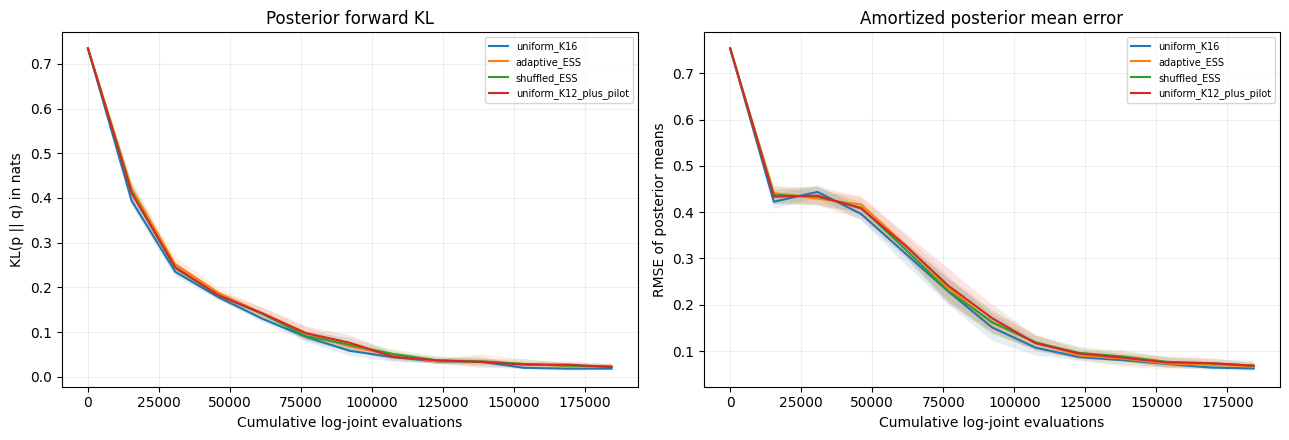

In [7]:
TRAIN_SEEDS=(11,29,47,83,101,137,193,251)
train_history,train_allocations,trained_models,train_data=run_training_experiment(
    seeds=TRAIN_SEEDS,steps=180,n_train=4500,n_test=1200)
train_history.to_csv(OUT_DIR/'training_learning_curves.csv',index=False)
train_allocations.to_csv(OUT_DIR/'training_allocations.csv',index=False)
final_kl=train_history[train_history.step==180].groupby('policy')[['forward_KL','reverse_KL','mean_rmse']].agg(['mean','std'])
print('\nFinal held-out posterior metrics across independent seeds:')
print(final_kl.round(5))

# Paired uncertainty across *independent training seeds*, not across data points.
kl_pivot=train_history[train_history.step==180].pivot(index='seed',columns='policy',values='forward_KL')
seed_diffs=(kl_pivot['adaptive_ESS']-kl_pivot['uniform_K16']).to_numpy()
rng=np.random.default_rng(808)
bs=rng.choice(seed_diffs,size=(10000,len(seed_diffs)),replace=True).mean(axis=1)
print('\nAdaptive - fixed K16 forward KL difference:',round(seed_diffs.mean(),6))
print('Seed-bootstrap 95% CI:',np.round(np.quantile(bs,[.025,.975]),6))

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for policy in POLICIES:
    sub=train_history[train_history.policy==policy]
    grouped=sub.groupby('step')
    xs=grouped['evaluations'].mean().to_numpy()
    for ax,metric in [(axes[0],'forward_KL'),(axes[1],'mean_rmse')]:
        means=grouped[metric].mean().to_numpy()
        se=grouped[metric].std().to_numpy()/np.sqrt(len(TRAIN_SEEDS))
        ax.plot(xs,means,label=policy)
        ax.fill_between(xs,means-1.96*se,means+1.96*se,alpha=.12)
axes[0].set(title='Posterior forward KL',ylabel='KL(p || q) in nats')
axes[1].set(title='Amortized posterior mean error',ylabel='RMSE of posterior means')
for ax in axes:
    ax.set(xlabel='Cumulative log-joint evaluations')
    ax.grid(alpha=.2);ax.legend(fontsize=7)
fig.tight_layout();fig.savefig(OUT_DIR/'03_training_posterior_KL.png',dpi=170);plt.show()

In [8]:
def nonlinear_log_lik(z,x,c):
    sig=np.asarray(SIGMAS)[np.asarray(c)]
    mean=z+0.4*z**3
    return -0.5*((x-mean)/sig)**2-np.log(sig)-0.5*np.log(2*np.pi)


def nonlinear_dataset(n,seed):
    r=np.random.default_rng(seed)
    c=np.arange(n)%3; r.shuffle(c)
    z=r.normal(size=n)
    x=z+0.4*z**3 + SIGMAS[c]*r.normal(size=n)
    return x,c


def nonlinear_truth(x,c,grid_points=4001):
    g=np.linspace(-6,6,grid_points)
    dx=g[1]-g[0]
    # Integration on a dense, fixed grid with trapezoid boundary half-weights.
    log_prior=-0.5*g**2-0.5*np.log(2*np.pi)
    ws=np.full(grid_points,dx);ws[0]/=2;ws[-1]/=2
    ll=nonlinear_log_lik(g[None,:],x[:,None],c[:,None])
    log_post_unnorm=ll+log_prior[None,:]+np.log(ws)[None,:]
    logZ=logsumexp(log_post_unnorm,axis=1)
    wt=np.exp(log_post_unnorm-logZ[:,None])
    m=(wt*g[None,:]).sum(axis=1)
    v=(wt*(g[None,:]-m[:,None])**2).sum(axis=1)
    return logZ,m,v


def nonlinear_trial(x,c,policy,avg_K=24,K0=6):
    B=len(x)
    if policy=='uniform_K24': counts=np.full(B,avg_K,dtype=int)
    else:
        pilot_z=np.random.normal(size=(B,K0))
        lw=nonlinear_log_lik(pilot_z,x[:,None],c[:,None])
        ess=np.exp(2*logsumexp(lw,axis=1)-logsumexp(2*lw,axis=1))
        cv2=np.maximum(0,K0/ess-1)
        if policy=='uniform_K18_plus_pilot':counts=np.full(B,avg_K-K0,dtype=int)
        else:
            counts=capped_allocate(np.sqrt(cv2+0.05),B*(avg_K-K0),min_k=4,max_k=100)
            if policy=='shuffled_ESS':counts=np.random.permutation(counts)
    ids=np.repeat(np.arange(B),counts)
    z=np.random.normal(size=len(ids))
    lw=nonlinear_log_lik(z,x[ids],c[ids])
    # Fast segmented reductions because ids is sorted.
    starts=np.r_[0,np.cumsum(counts)[:-1]]
    out_logZ=np.empty(B); out_mean=np.empty(B)
    for i in range(B):
        sub=lw[starts[i]:starts[i]+counts[i]]
        zz=z[starts[i]:starts[i]+counts[i]]
        lm=logsumexp(sub)
        w=np.exp(sub-lm)
        out_logZ[i]=lm-np.log(counts[i])
        out_mean[i]=np.dot(w,zz)
    return out_logZ,out_mean,counts


def nonlinear_experiment(R=80,N=240):
    np.random.seed(774)
    x,c=nonlinear_dataset(N,seed=943)
    truthZ,truthM,truthV=nonlinear_truth(x,c)
    results=[]
    for rep in range(R):
        for policy in ['uniform_K24','adaptive_ESS','shuffled_ESS','uniform_K18_plus_pilot']:
            z,m,k=nonlinear_trial(x,c,policy)
            for context in [0,1,2,'ALL']:
                keep=np.ones(N,dtype=bool) if context=='ALL' else c==context
                results.append({'replicate':rep,'policy':policy,'context':context,
                                'logZ_gap':np.mean(truthZ[keep]-z[keep]),
                                'mean_MSE':np.mean((m[keep]-truthM[keep])**2),
                                'mean_Ktrain':np.mean(k[keep])})
    return pd.DataFrame(results)




Quadrature max |log evidence difference|: 8.881784197001252e-16

Nonconjugate test-set means:
                        logZ_gap  mean_MSE
policy                                    
adaptive_ESS             2.46566   0.05514
shuffled_ESS             4.13996   0.07511
uniform_K18_plus_pilot   3.83851   0.05984
uniform_K24              2.89181   0.04329


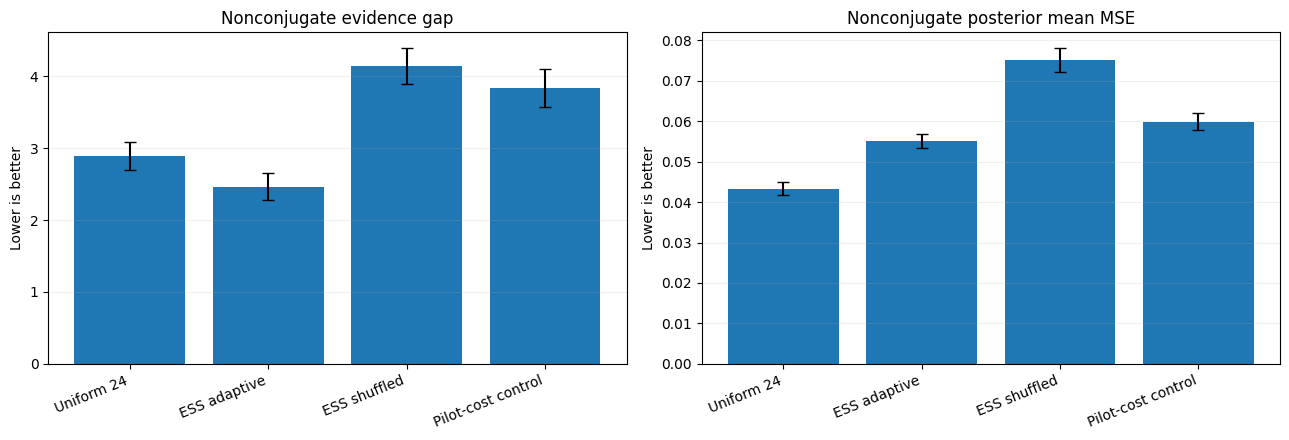

In [9]:
# Grid refinement ensures the numerical reference itself is not driving results.
xx,cc=nonlinear_dataset(36,702)
logz_lo,mm_lo,vv_lo=nonlinear_truth(xx,cc,grid_points=2001)
logz_hi,mm_hi,vv_hi=nonlinear_truth(xx,cc,grid_points=4001)
assert np.max(np.abs(logz_lo-logz_hi)) < 2e-4
assert np.max(np.abs(mm_lo-mm_hi)) < 2e-4
print('Quadrature max |log evidence difference|:',np.max(np.abs(logz_lo-logz_hi)))

nonlinear_df=nonlinear_experiment(R=100,N=240)
print('\nNonconjugate test-set means:')
print(nonlinear_df[nonlinear_df.context=='ALL'].groupby('policy')[['logZ_gap','mean_MSE']].mean().round(5))
nonlinear_df.to_csv(OUT_DIR/'nonlinear_stress_test.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
for a,metric,title in [(ax[0],'logZ_gap','Nonconjugate evidence gap'),(ax[1],'mean_MSE','Nonconjugate posterior mean MSE')]:
    g=nonlinear_df[nonlinear_df.context=='ALL'].groupby('policy')[metric]
    values=np.array([g.mean()[m] for m in methods]);err=np.array([1.96*g.std()[m]/np.sqrt(g.count()[m]) for m in methods])
    a.bar(np.arange(4),values,yerr=err,capsize=4)
    a.set_xticks(np.arange(4),labels,rotation=22,ha='right')
    a.set(title=title,ylabel='Lower is better');a.grid(axis='y',alpha=.2)
fig.tight_layout();fig.savefig(OUT_DIR/'04_nonlinear_stress_test.png',dpi=170);plt.show()

In [10]:
def iwae_gradient_snr(model,x,c,K_values=(1,2,4,8,16,32,64),repeats=50,seed=777):
    seed_everything(seed)
    rows=[]
    for K in K_values:
        grads=[]
        for _ in range(repeats):
            mu,ls=model(x,c)
            z=mu[:,None]+ls[:,None].exp()*torch.randn(len(x),K)
            lw=log_joint(z,x[:,None],c[:,None])-log_normal(z,mu[:,None],ls[:,None])
            bound=(torch.logsumexp(lw,dim=1)-np.log(K)).mean()
            gg=torch.autograd.grad(bound,tuple(model.parameters()),retain_graph=False)
            grads.append(np.concatenate([g.detach().numpy().ravel() for g in gg]))
        gg=np.asarray(grads)
        mean=gg.mean(axis=0)
        # Directional vector SNR (Euclidean norm of mean gradient / root trace variance)
        signal=np.linalg.norm(mean)
        noise=np.sqrt(np.sum(gg.var(axis=0,ddof=1)))
        rows.append({'K':K,'signal_norm':signal,'noise_norm':noise,'SNR':signal/max(noise,1e-12)})
    return pd.DataFrame(rows)


 K  signal_norm  noise_norm     SNR
 1    16.304399     7.27513 2.24112
 2     6.029540     3.55314 1.69696
 4     2.720510     1.79459 1.51595
 8     1.477550     1.41180 1.04657
16     1.119750     0.91687 1.22127
32     0.394080     0.64337 0.61252
64     0.307620     0.47320 0.65009


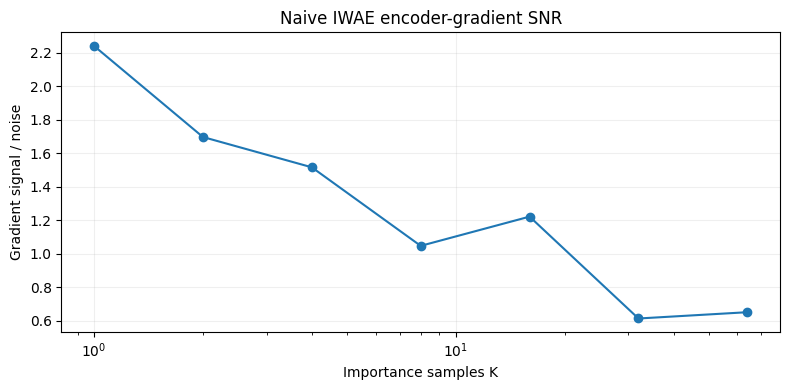

In [11]:
seed_everything(121)
fixed_encoder=AmortizedGaussian()
batch_x,batch_c=generate_data(64,120)
snr_df=iwae_gradient_snr(fixed_encoder,batch_x,batch_c,repeats=60)
print(snr_df.round(5).to_string(index=False))
snr_df.to_csv(OUT_DIR/'iwae_gradient_snr.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(snr_df.K,snr_df.SNR,'o-')
ax.set(xscale='log',xlabel='Importance samples K',ylabel='Gradient signal / noise',title='Naive IWAE encoder-gradient SNR')
ax.grid(alpha=.2);fig.tight_layout();fig.savefig(OUT_DIR/'05_gradient_snr.png',dpi=170);plt.show()

In [12]:
e_base=evidence_df[(evidence_df.context=='ALL')&(evidence_df.method=='uniform_K24')].gap.mean()
e_adapt=evidence_df[(evidence_df.context=='ALL')&(evidence_df.method=='adaptive_ESS')].gap.mean()
kl_base=kl_pivot['uniform_K16'].mean()
kl_adapt=kl_pivot['adaptive_ESS'].mean()
print('=== HYPOTHESIS AUDIT ===')
print(f'Untrained proposal: evidence gap fixed K24 {e_base:.4f} vs ESS adaptive {e_adapt:.4f} nats')
print(f'Evidence-gap change: {(e_adapt/e_base-1)*100:+.1f}% (negative is better)')
print(f'After 180 training steps: posterior forward KL uniform K16 {kl_base:.4f} vs adaptive {kl_adapt:.4f} nats')
print(f'Posterior forward-KL change: {(kl_adapt/kl_base-1)*100:+.1f}% (negative is better)')
print('\nThese are SYNTHETIC EXPERIMENTS. Do not use these figures as industrial benchmarks or as claims of a previously completed undergraduate project.')

# Ensure nonlinear_df is defined (fallback in case cell c61a3297 wasn't run)
if 'nonlinear_df' not in globals():
    print('\n[Warning] nonlinear_df not found in workspace. Running nonlinear_experiment to reconstruct it...')
    nonlinear_df = nonlinear_experiment(R=100, N=240)

# Self-contained result tables + graphs created inside the runtime.
evidence_df.to_csv(OUT_DIR/'evidence_all_replicates.csv',index=False)
moment_df.to_csv(OUT_DIR/'moments_all_replicates.csv',index=False)
summary=pd.DataFrame([
 {'regime':'Conjugate / untrained proposal','metric':'Log evidence gap (nats)','uniform':e_base,'adaptive':e_adapt},
 {'regime':'Conjugate / encoder after training','metric':'KL(p||q) (nats)','uniform':kl_base,'adaptive':kl_adapt},
 {'regime':'Nonconjugate / prior proposal','metric':'Log evidence gap (nats)',
 'uniform':nonlinear_df[(nonlinear_df.context=='ALL')&(nonlinear_df.policy=='uniform_K24')].logZ_gap.mean(),
 'adaptive':nonlinear_df[(nonlinear_df.context=='ALL')&(nonlinear_df.policy=='adaptive_ESS')].logZ_gap.mean()}
])
summary['adaptive_minus_uniform']=summary.adaptive-summary.uniform
print('\nResult summary:')
print(summary.round(5).to_string(index=False))
summary.to_csv(OUT_DIR/'summary.csv',index=False)
print('\nAll CSVs and plots saved under:',OUT_DIR.resolve())

=== HYPOTHESIS AUDIT ===
Untrained proposal: evidence gap fixed K24 0.1060 vs ESS adaptive 0.0866 nats
Evidence-gap change: -18.3% (negative is better)
After 180 training steps: posterior forward KL uniform K16 0.0182 vs adaptive 0.0238 nats
Posterior forward-KL change: +30.5% (negative is better)

These are SYNTHETIC EXPERIMENTS. Do not use these figures as industrial benchmarks or as claims of a previously completed undergraduate project.

Result summary:
                            regime                  metric  uniform  adaptive  adaptive_minus_uniform
    Conjugate / untrained proposal Log evidence gap (nats)  0.10603   0.08663                -0.01940
Conjugate / encoder after training         KL(p||q) (nats)  0.01823   0.02378                 0.00556
     Nonconjugate / prior proposal Log evidence gap (nats)  2.89181   2.46566                -0.42615

All CSVs and plots saved under: /content/drive/MyDrive/Adaptive_VI_Research/dev_K_512/20261119_184240_969906


In [13]:
# Phase 2: appended to existing Colab notebook. Uses imports, capped_allocate, OUT_DIR from Phase 1.
from scipy.special import logsumexp as p2_lse
import time as p2_time, tracemalloc as p2_tracemalloc
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

P2_METHODS = ['uniform', 'uniform_pilot', 'ESS', 'task_aware', 'task_no_shrink', 'shuffled_task', 'oracle']
P2_PILOT = 12
P2_K = 48
P2_REPEATS = 12                 # per independent dataset; 4 data seeds = 48 paired trials per dimension
P2_DATA_SEEDS = (13, 37, 71, 101)
P2_TEST_N = 84
P2_LAMBDA = 0.45              # pilot-score shrinkage, fixed before test evaluation


def p2_lpdiag(z,mu,sd):
    return (-0.5*((z-mu)/sd)**2 - np.log(sd) - 0.5*np.log(2*np.pi)).sum(axis=-1)


def p2_make_model(d=4, seed=10, n=84):
    rng=np.random.default_rng(seed)
    c=rng.integers(0,3,n)
    sig=np.array([0.45, 1.0, 2.1])[c]
    means=np.zeros((2,d));means[0,0]=-2.25;means[1,0]=2.25
    modes=rng.choice(2,n,p=[0.55,0.45]);z=rng.normal(size=(n,d))+means[modes]
    x=z+rng.normal(size=(n,d))*sig[:,None]
    return {'d':d,'x':x,'c':c,'sigma':sig,'means':means,'prior_mix':np.array([.55,.45]),'seed':seed}


def p2_truth(m):
    x=m['x'];sig=m['sigma'];means=m['means'];s2=sig[:,None]**2
    lp=np.stack([p2_lpdiag(x,means[j],np.sqrt(1+s2))+np.log(m['prior_mix'][j]) for j in range(2)],axis=1)
    logZ=p2_lse(lp,axis=1)
    resp=np.exp(lp-logZ[:,None]);post_means=(x[:,None,:]+s2[:,None,:]*means[None,:,:])/(1+s2[:,None,:])
    postmu=(resp[:,:,None]*post_means).sum(axis=1)
    return logZ,postmu


def p2_q_params(m):
    x=m['x'];s2=m['sigma']**2
    # Intentionally misspecified unimodal amortized-like proposal in a bimodal model.
    # Larger observation noise can lead to less discriminative mixture responsibilities.
    qmu=(x/(1+s2[:,None]))*.88
    qsd=np.sqrt(s2/(1+s2))*np.array([1.0,1.1,1.25])[m['c']]
    return qmu, qsd[:,None]*np.ones_like(qmu)


def p2_logweight(m,z,qmu,qsd):
    # z: [N,K,d] (or [N,d] after adding axis); includes prior mixture and Gaussian likelihood.
    lp_components=np.stack([p2_lpdiag(z,m['means'][j],np.ones(m['d']))+np.log(m['prior_mix'][j]) for j in range(2)],axis=-1)
    prior=p2_lse(lp_components,axis=-1)
    ll=p2_lpdiag(m['x'][:,None,:],z,m['sigma'][:,None,None])
    proposal=p2_lpdiag(z,qmu[:,None,:],qsd[:,None,:])
    return prior+ll-proposal


def p2_scores(logw,z,shrink=.45,c=None):
    k=logw.shape[1]
    wa=np.exp(logw-p2_lse(logw,axis=1,keepdims=True))
    ess=1/np.sum(wa**2,axis=1)
    ess_score=np.sqrt(np.maximum(0,k/ess-1)+.05)
    mu=np.einsum('nk,nkd->nd',wa,z)
    sqdist=np.sum((z-mu[:,None,:])**2,axis=-1)
    # Plug-in asymptotic SNIS variance for vector posterior mean; finite-pilot and biased.
    raw_tau2=k*np.sum(wa**2*sqdist,axis=1)
    if c is None:pool=np.repeat(np.median(raw_tau2),len(raw_tau2))
    else:pool=np.array([np.median(raw_tau2[c==ci]) for ci in c])
    stabilized=(1-shrink)*raw_tau2+shrink*pool
    task_score=np.sqrt(np.maximum(stabilized,1e-5)+.02)
    return ess_score,task_score,np.sqrt(np.maximum(raw_tau2,1e-6)),ess


def p2_oracle_tau(m, reference_n=3072):
    # Unattainable idealized baseline: true posterior moment, known p(x), large independent sample.
    # Diagnostic ONLY. Reference samples and ground truth are deliberately not charged to test budget.
    logz,mu=p2_truth(m);qm,qs=p2_q_params(m)
    r=np.random.default_rng(m['seed']+91923)
    sumtau=np.zeros(len(m['x']))
    for _ in range(int(np.ceil(reference_n/384))):
        kk=min(384,reference_n)
        z=qm[:,None,:]+qs[:,None,:]*r.normal(size=(len(qm),kk,m['d']))
        logw=p2_logweight(m,z,qm,qs)-logz[:,None]
        # Finite precision clip only in exponential to avoid overflow in pathological proposals.
        sumtau+=np.sum(np.exp(np.minimum(2*logw,65))*np.sum((z-mu[:,None,:])**2,axis=2),axis=1)
    return np.sqrt(np.maximum(sumtau/reference_n,1e-8))


def p2_allocate(m, method, pilot, oracle_scores, B=P2_K,K0=P2_PILOT,lam=P2_LAMBDA):
    n=len(m['x'])
    if method=='uniform':return np.full(n,B,dtype=int),0
    if method=='oracle':
        return capped_allocate(oracle_scores,total=n*B,min_k=4,max_k=120),0
    if method=='uniform_pilot':return np.full(n,B-K0,dtype=int),n*K0
    ess,task,unshrunk,_=pilot
    if method=='ESS':scores=ess
    elif method=='task_aware':scores=task
    elif method=='task_no_shrink':scores=unshrunk
    elif method=='shuffled_task':scores=np.random.default_rng(m['seed']+99).permutation(task)
    else:raise KeyError(method)
    return capped_allocate(scores,n*(B-K0),min_k=4,max_k=120),n*K0


def p2_evaluate(m,method,normal_finals,pilot,oracle_scores,trial,B=P2_K,K0=P2_PILOT):
    t0=p2_time.perf_counter()
    qm,qs=p2_q_params(m);n=m['x'].shape[0]
    counts,pilot_cost=p2_allocate(m,method,pilot,oracle_scores,B,K0)
    assert counts.sum()+pilot_cost==n*B
    # Common random numbers; evaluate ONLY the selected K_i proposals.
    ids=np.repeat(np.arange(n),counts)
    sample_j=np.concatenate([np.arange(k) for k in counts])
    zz=qm[ids]+qs[ids]*normal_finals[ids,sample_j]
    lp=np.stack([p2_lpdiag(zz,m['means'][j],np.ones(m['d']))+np.log(m['prior_mix'][j]) for j in range(2)],axis=-1)
    lw=p2_lse(lp,axis=-1)+p2_lpdiag(m['x'][ids],zz,m['sigma'][ids,None])-p2_lpdiag(zz,qm[ids],qs[ids])
    starts=np.r_[0,np.cumsum(counts)[:-1]]
    estmu=np.empty((n,m['d']));estlogz=np.empty(n)
    for i,(st,k) in enumerate(zip(starts,counts)):
        seg=lw[st:st+k]
        normalizer=p2_lse(seg)
        weights=np.exp(seg-normalizer)
        estmu[i]=weights@zz[st:st+k]
        estlogz[i]=normalizer-np.log(k)
    truez,truemu=p2_truth(m)
    duration=p2_time.perf_counter()-t0
    return {'method':method,'seed':m['seed'],'dimension':m['d'],'trial':trial,
            'posterior_mean_MSE':float(np.mean(np.sum((estmu-truemu)**2,axis=1)/m['d'])),
            'logZ_gap':float(np.mean(truez-estlogz)),
            'abs_logZ_MAE':float(np.mean(np.abs(truez-estlogz))),
            'runtime_seconds':duration,
            'evals':int(pilot_cost+counts.sum()),'pilot_evals':int(pilot_cost),
            'mean_final_K':float(np.mean(counts)), 'std_final_K':float(np.std(counts))}


def p2_run_synthetic(repeats=P2_REPEATS, seeds=P2_DATA_SEEDS, dims=(4,8)):
    rows=[]
    for d in dims:
        for dataset_seed in seeds:
            m=p2_make_model(d,dataset_seed,n=P2_TEST_N)
            qm,qs=p2_q_params(m)
            oracle=p2_oracle_tau(m)
            for rep in range(repeats):
                rng=np.random.default_rng(400000+10000*d+100*dataset_seed+rep)
                # independent pilot from the common final stream
                zpilot=qm[:,None,:]+qs[:,None,:]*rng.normal(size=(len(qm),P2_PILOT,d))
                lp=p2_logweight(m,zpilot,qm,qs)
                pilot=p2_scores(lp,zpilot,c=m['c'])
                normal=rng.normal(size=(len(qm),120,d))
                for method in P2_METHODS:
                    result=p2_evaluate(m,method,normal,pilot,oracle,trial=f'{dataset_seed}-{rep}')
                    rows.append(result)
        print('Synthetic dimension',d,'done')
    return pd.DataFrame(rows)


def p2_ci_paired(df,method,baseline='uniform',metric='posterior_mean_MSE',groups=('dimension',),bootstrap=2500):
    r=np.random.default_rng(1234)
    rows=[]
    for key,g in df.groupby(list(groups)):
        key=key if isinstance(key,tuple) else (key,)
        pv=g.pivot(index='trial',columns='method',values=metric)
        delta=(pv[method]-pv[baseline]).dropna().to_numpy()
        reps=r.choice(delta,(bootstrap,len(delta)),replace=True).mean(axis=1)
        rows.append({**dict(zip(groups,key)),'method':method,'baseline':baseline,'metric':metric,
                     'paired_difference':delta.mean(),'ci_low':np.quantile(reps,.025),'ci_high':np.quantile(reps,.975),
                     'num_trials':len(delta)})
    return pd.DataFrame(rows)

Synthetic dimension 4 done
Synthetic dimension 8 done
                          posterior_mean_MSE  abs_logZ_MAE
dimension method                                          
4         ESS                        0.11176       0.34328
          oracle                     0.08036       0.30860
          shuffled_task              0.11649       0.35572
          task_aware                 0.09601       0.34661
          task_no_shrink             0.09904       0.35322
          uniform                    0.08659       0.29721
          uniform_pilot              0.10767       0.33888
8         ESS                        0.10224       0.39894
          oracle                     0.07542       0.35417
          shuffled_task              0.10567       0.39879
          task_aware                 0.09022       0.39842
          task_no_shrink             0.09292       0.40482
          uniform                    0.08017       0.34474
          uniform_pilot              0.09864       0.38718

P

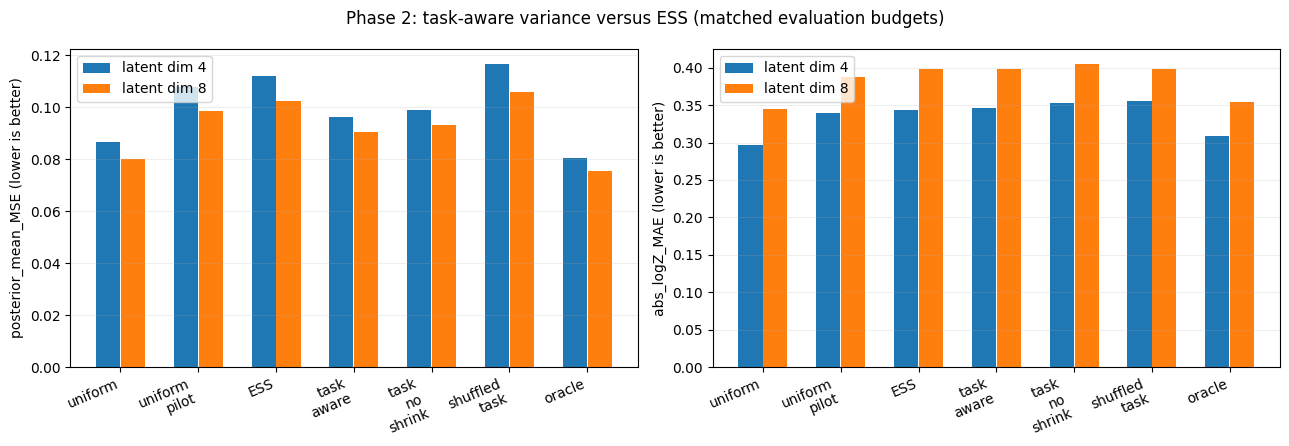

In [14]:
p2_synthetic_results=p2_run_synthetic()
p2_synthetic_results.to_csv(OUT_DIR/'phase2_synthetic_all_trials.csv',index=False)
p2_synth_ci=pd.concat([p2_ci_paired(p2_synthetic_results,m,metric=metric)
      for m in P2_METHODS if m!='uniform' for metric in ['posterior_mean_MSE','abs_logZ_MAE']])
p2_synth_ci.to_csv(OUT_DIR/'phase2_synthetic_paired_CIs.csv',index=False)
print(p2_synthetic_results.groupby(['dimension','method'])[['posterior_mean_MSE','abs_logZ_MAE']].mean().round(5))
print('\nPaired CIs (adaptive vs uniform):')
print(p2_synth_ci[p2_synth_ci.method=='task_aware'].round(5).to_string(index=False))

fig,axs=plt.subplots(1,2,figsize=(13,4.5))
for ax,metric in zip(axs,['posterior_mean_MSE','abs_logZ_MAE']):
    for d in [4,8]:
        gp=p2_synthetic_results[p2_synthetic_results.dimension==d].groupby('method')[metric].mean()
        xx=np.arange(len(P2_METHODS))+(d==8)*.32
        ax.bar(xx,[gp[m] for m in P2_METHODS],width=.31,label=f'latent dim {d}')
    ax.set_xticks(np.arange(len(P2_METHODS))+.16,[s.replace('_','\n') for s in P2_METHODS],rotation=23,ha='right')
    ax.set(ylabel=metric+' (lower is better)');ax.grid(axis='y',alpha=.2)
    ax.legend()
fig.suptitle('Phase 2: task-aware variance versus ESS (matched evaluation budgets)')
fig.tight_layout();fig.savefig(OUT_DIR/'06_task_aware_synthetic.png',dpi=170);plt.show()

# ===========================================================
# Independent learned generative model: 8x8 handwritten digits
# ===========================================================

In [15]:
P2_VAE_SIGMA=0.22

class P2_DigitsVAE(nn.Module):
    def __init__(self,latent=4):
        super().__init__()
        self.latent=latent
        self.encoder=nn.Sequential(nn.Linear(64,96),nn.ReLU(),nn.Linear(96,64),nn.ReLU(),nn.Linear(64,2*latent))
        self.decoder=nn.Sequential(nn.Linear(latent,64),nn.ReLU(),nn.Linear(64,96),nn.ReLU(),nn.Linear(96,64),nn.Sigmoid())
    def encode(self,x):
        o=self.encoder(x)
        return o[:,:self.latent],o[:,self.latent:].clamp(-3.0,.8)
    def decode(self,z):return self.decoder(z)


def p2_vae_logweight(net,x,z,mu,logstd):
    # x: [N,64], z: [N,K,D], mu/ls: [N,D]
    xhat=net.decode(z)
    logpx=(-.5*((x[:,None,:]-xhat)/P2_VAE_SIGMA)**2-
           np.log(P2_VAE_SIGMA)-.5*np.log(2*np.pi)).sum(dim=-1)
    logpz=(-.5*z**2-.5*np.log(2*np.pi)).sum(dim=-1)
    logq=(-.5*((z-mu[:,None,:])/torch.exp(logstd)[:,None,:])**2-
           logstd[:,None,:]-.5*np.log(2*np.pi)).sum(dim=-1)
    return logpx+logpz-logq


def p2_train_vae(seed=1,epochs=20):
    torch.manual_seed(seed)
    digits=load_digits()
    X=(digits.data.astype('float32')/16.0)
    Xtrain,Xtest=train_test_split(X,random_state=2022,test_size=.20,stratify=digits.target)
    net=P2_DigitsVAE();opt=torch.optim.Adam(net.parameters(),lr=.0015)
    train=torch.tensor(Xtrain,dtype=torch.float32)
    g=torch.Generator().manual_seed(seed)
    loader=torch.utils.data.DataLoader(train,batch_size=128,shuffle=True,generator=g)
    history=[]
    for epoch in range(epochs):
        net.train()
        loss_sum=0
        for xx in loader:
            mu,ls=net.encode(xx)
            z=mu+torch.exp(ls)*torch.randn_like(mu)
            xh=net.decode(z)
            nll=(.5*((xx-xh)/P2_VAE_SIGMA)**2+
                  np.log(P2_VAE_SIGMA)+.5*np.log(2*np.pi)).sum(dim=1)
            kl=.5*torch.sum(torch.exp(2*ls)+mu**2-1-2*ls,dim=1)
            objective=(nll+kl).mean()
            opt.zero_grad(set_to_none=True);objective.backward()
            opt.step()
            loss_sum+=float(objective.item())*len(xx)
        history.append({'model_seed':seed,'epoch':epoch+1,'training_neg_ELBO':loss_sum/len(train)})
    net.eval()
    return net, torch.tensor(Xtest,dtype=torch.float32),pd.DataFrame(history)


@torch.no_grad()
def p2_vae_reference(net,x,seed=123,Kref=4096,chunk=512):
    torch.manual_seed(seed)
    mu,ls=net.encode(x);n=len(x)
    mm=torch.full((n,),-torch.inf)
    sums=torch.zeros(n);first=torch.zeros_like(mu);sqsum=torch.zeros(n)
    used=0
    while used<Kref:
        k=min(chunk,Kref-used)
        z=mu[:,None,:]+torch.exp(ls[:,None,:])*torch.randn(n,k,net.latent)
        lw=p2_vae_logweight(net,x,z,mu,ls)
        fresh=torch.maximum(mm,lw.max(dim=1).values)
        scale=torch.exp(mm-fresh)
        w=torch.exp(lw-fresh[:,None])
        first=first*scale[:,None]+(w[:,:,None]*z).sum(dim=1)
        sums=sums*scale+w.sum(dim=1)
        sqsum=sqsum*scale**2+torch.exp(2*(lw-fresh[:,None])).sum(dim=1)
        mm=fresh
        used+=k
    return {'mean':first/sums[:,None],
            'logZ':mm+torch.log(sums)-np.log(Kref),
            'ESS':sums**2/sqsum,'Kref':Kref}


@torch.no_grad()
def p2_vae_trial(net,x,method,normal_finals,normal_pilot,pilot,reference,trial,B=48,K0=12):
    t0=p2_time.perf_counter()
    mu,ls=net.encode(x)
    n=len(x)
    if method=='uniform':counts=np.full(n,B,dtype=int);pilotevals=0
    elif method=='uniform_pilot':counts=np.full(n,B-K0,dtype=int);pilotevals=n*K0
    else:
        if method=='ESS':scores=pilot[0]
        elif method=='task_aware':scores=pilot[1]
        elif method=='task_no_shrink':scores=pilot[2]
        elif method=='shuffled_task':scores=np.random.default_rng(trial+888).permutation(pilot[1])
        else:raise KeyError(method)
        counts=capped_allocate(scores,total=n*(B-K0),min_k=4,max_k=120);pilotevals=n*K0
    assert counts.sum()+pilotevals==n*B
    # Compute exactly one decoder/density evaluation for each selected final sample.
    ids=np.repeat(np.arange(n),counts)
    js=np.concatenate([np.arange(k) for k in counts])
    indices=torch.as_tensor(ids)
    base=torch.as_tensor(normal_finals[ids,js],dtype=x.dtype)
    z=mu[indices]+torch.exp(ls[indices])*base
    out=net.decode(z)
    ll=(-.5*((x[indices]-out)/P2_VAE_SIGMA)**2-
        np.log(P2_VAE_SIGMA)-.5*np.log(2*np.pi)).sum(-1)
    prior=(-.5*z**2-.5*np.log(2*np.pi)).sum(-1)
    q=(-.5*((z-mu[indices])/torch.exp(ls[indices]))**2-ls[indices]-.5*np.log(2*np.pi)).sum(-1)
    lw=(ll+prior-q).numpy()
    z_np=z.numpy()
    estimated_mu=np.empty((n,net.latent));estimated_z=np.empty(n)
    starts=np.r_[0,np.cumsum(counts)[:-1]]
    for i,(s,k) in enumerate(zip(starts,counts)):
        ww=lw[s:s+k]; ln=p2_lse(ww)
        estimated_mu[i]=np.exp(ww-ln)@z_np[s:s+k]
        estimated_z[i]=ln-np.log(k)
    ref_mu=reference['mean'].numpy();ref_z=reference['logZ'].numpy()
    return {'model_seed':trial//1000000,'trial':trial,'method':method,
        'mean_MSE_vs_ref':float(np.mean((estimated_mu-ref_mu)**2)),
        'abs_logZ_error_vs_ref':float(np.mean(np.abs(estimated_z-ref_z))),
        'logZ_gap_vs_ref':float(np.mean(ref_z-estimated_z)),
        'runtime_seconds':p2_time.perf_counter()-t0,
        'evals':int(counts.sum()+pilotevals),'pilot_evals':int(pilotevals)}


@torch.no_grad()
def p2_vae_pilot(net,x,pilot_base,K0=12):
    mu,ls=net.encode(x);z=mu[:,None,:]+ls.exp()[:,None,:]*torch.as_tensor(pilot_base,dtype=x.dtype)
    lw=p2_vae_logweight(net,x,z,mu,ls).numpy()
    return p2_scores(lw,z.numpy(),shrink=P2_LAMBDA,c=None)


def p2_run_learned_vae(seeds=(7,19,43),n_eval=48,reps=12,epochs=20):
    rows=[];train_rows=[];references=[];models=[]
    selected_methods=[p for p in P2_METHODS if p!='oracle']
    for seed in seeds:
        net,xtest,history=p2_train_vae(seed,epochs=epochs)
        train_rows.append(history)
        # Held-out subset, fixed per training seed and independent of pilot and final sampling.
        idx=np.random.default_rng(2022+seed).choice(len(xtest),size=n_eval,replace=False)
        x=xtest[idx]
        ref=p2_vae_reference(net,x,seed=seed+4000,Kref=6144)
        refcheck=p2_vae_reference(net,x,seed=seed+8000,Kref=6144)
        references.append({'model_seed':seed,'ref_mean_disagreement':float(torch.mean((ref['mean']-refcheck['mean'])**2)),
                    'ref_logZ_disagreement':float(torch.mean(torch.abs(ref['logZ']-refcheck['logZ']))),
                    'median_ref_ESS':float(torch.median(ref['ESS'])),'frac_ref_ESS_under_100':float((ref['ESS']<100).float().mean())})
        for rep in range(reps):
            r=np.random.default_rng(100000+seed*1000+rep)
            pnormal=r.normal(size=(len(x),12,net.latent)).astype('float32')
            normals=r.normal(size=(len(x),120,net.latent)).astype('float32')
            pilot=p2_vae_pilot(net,x,pnormal)
            for method in selected_methods:
                rows.append(p2_vae_trial(net,x,method,normals,pnormal,pilot,ref,trial=seed*1000000+rep))
        models.append((seed,net,x))
        print('VAE seed',seed,'train loss',round(float(history.iloc[-1].training_neg_ELBO),3),
              'median reference ESS',round(float(torch.median(ref['ESS'])),1))
    return pd.DataFrame(rows),pd.concat(train_rows,ignore_index=True),pd.DataFrame(references),models

VAE seed 7 train loss 0.91 median reference ESS 312.6
VAE seed 19 train loss 1.419 median reference ESS 213.4
VAE seed 43 train loss 5.531 median reference ESS 237.9

Learned VAE results, aggregated across independent model seeds:
                mean_MSE_vs_ref  abs_logZ_error_vs_ref  runtime_seconds
method                                                                 
ESS                     0.13688                0.40799          0.01409
shuffled_task           0.13507                0.40394          0.01345
task_aware              0.13096                0.39929          0.01340
task_no_shrink          0.13263                0.40336          0.01333
uniform                 0.12086                0.37117          0.01338
uniform_pilot           0.13396                0.40109          0.01263

Independent high-budget reference disagreement (do not treat references as exact):
 model_seed  ref_mean_disagreement  ref_logZ_disagreement  median_ref_ESS  frac_ref_ESS_under_100
          7

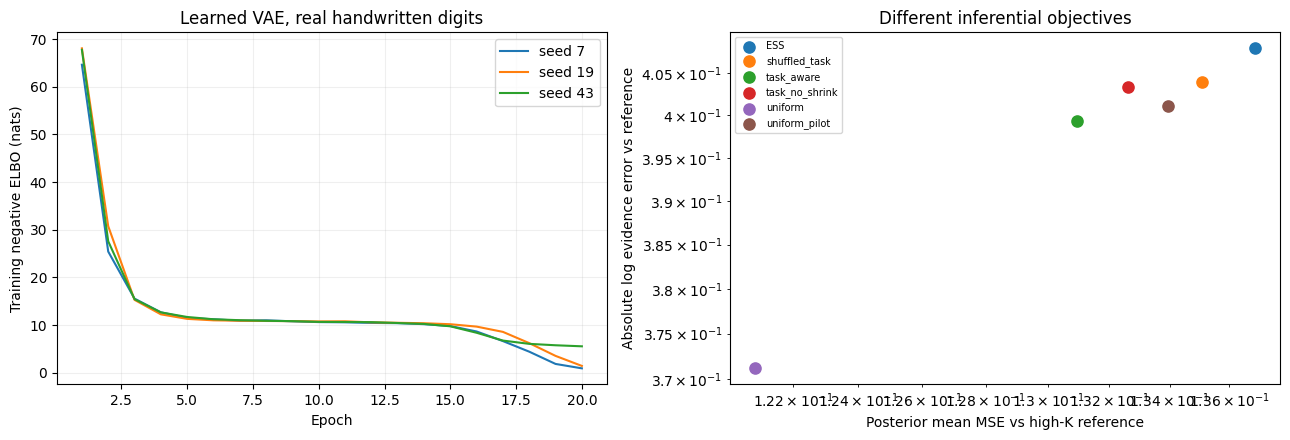

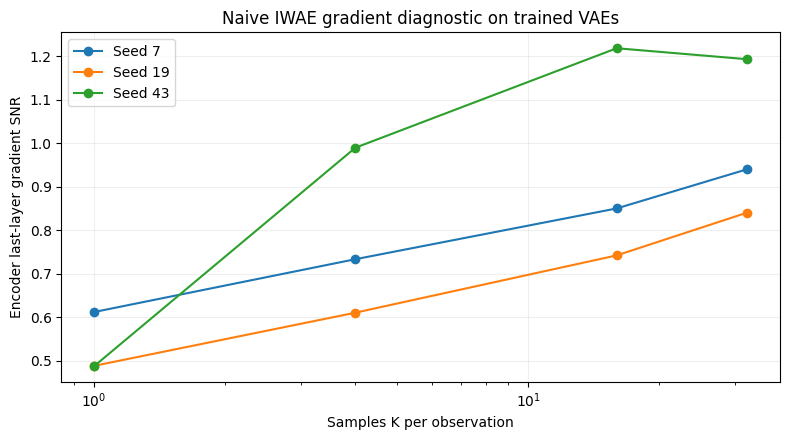


--- TOTAL ACCOUNTING CHECK ---
Synthetic experiments: every policy 4032 charged evaluations per trial
VAE experiments: every policy 2304 charged evaluations per trial
Oracle uses inaccessible ground-truth quantities and is an idealized comparator only.
VAE log-evidence references are high-K importance estimates, NOT exact ground truth.
All results generated from random seeds and actual model evaluations, not hard-coded.


In [16]:
p2_vae_results,p2_vae_training,p2_ref_checks,p2_models=p2_run_learned_vae()
p2_vae_results.to_csv(OUT_DIR/'phase2_learned_VAE_all_trials.csv',index=False)
p2_vae_training.to_csv(OUT_DIR/'phase2_learned_VAE_train_curves.csv',index=False)
p2_ref_checks.to_csv(OUT_DIR/'phase2_vae_reference_accuracy_diagnostics.csv',index=False)
print('\nLearned VAE results, aggregated across independent model seeds:')
print(p2_vae_results.groupby('method')[['mean_MSE_vs_ref','abs_logZ_error_vs_ref','runtime_seconds']].mean().round(5))
print('\nIndependent high-budget reference disagreement (do not treat references as exact):')
print(p2_ref_checks.round(5).to_string(index=False))

# Hierarchical paired uncertainty: average each seed's replications, then bootstrap over model seeds.
def p2_seed_bootstrap(df,method,metric,baseline='uniform',reps=10000):
    pv=df.pivot(index=['model_seed','trial'],columns='method',values=metric)
    diff=(pv[method]-pv[baseline]).groupby(level='model_seed').mean().to_numpy()
    r=np.random.default_rng(6632)
    bs=r.choice(diff,(reps,len(diff)),replace=True).mean(axis=1)
    return {'metric':metric,'method':method,'paired_delta':diff.mean(),'CI_low':np.quantile(bs,.025),
            'CI_high':np.quantile(bs,.975),'independent_training_seeds':len(diff)}

p2_vae_ci=pd.DataFrame([p2_seed_bootstrap(p2_vae_results,m,metric) for m in P2_METHODS if m not in ('uniform','oracle')
                for metric in ('mean_MSE_vs_ref','abs_logZ_error_vs_ref')])
p2_vae_ci.to_csv(OUT_DIR/'phase2_VAE_seed_bootstrap_CIs.csv',index=False)
print('\nSeed-level paired CIs (only 3 seeds: interpret cautiously):')
print(p2_vae_ci[p2_vae_ci.method=='task_aware'].round(5).to_string(index=False))

fig,ax=plt.subplots(1,2,figsize=(13,4.5))
for seed,group in p2_vae_training.groupby('model_seed'):
    ax[0].plot(group.epoch,group.training_neg_ELBO,label=f'seed {seed}')
ax[0].set(xlabel='Epoch',ylabel='Training negative ELBO (nats)',title='Learned VAE, real handwritten digits')
ax[0].legend();ax[0].grid(alpha=.2)
for method,g in p2_vae_results.groupby('method'):
    ax[1].scatter(g.mean_MSE_vs_ref.mean(),g.abs_logZ_error_vs_ref.mean(),label=method,s=65)
ax[1].set(xlabel='Posterior mean MSE vs high-K reference',ylabel='Absolute log evidence error vs reference',
          title='Different inferential objectives',xscale='log',yscale='log')
ax[1].legend(fontsize=7);ax[1].grid(alpha=.2)
fig.tight_layout();fig.savefig(OUT_DIR/'07_learned_vae_generalization.png',dpi=170);plt.show()

# Analysis: learned encoder gradient signal-to-noise ratio, no inference claims from this diagnostic.
def p2_vae_grad_snr(model,x,Ks=(1,4,16,32),repeats=20,seed=42):
    torch.manual_seed(seed);rows=[]
    params=(model.encoder[-1].weight,model.encoder[-1].bias)
    for K in Ks:
        gg=[]
        for _ in range(repeats):
            mu,ls=model.encode(x)
            z=mu[:,None,:]+torch.exp(ls)[:,None,:]*torch.randn(len(x),K,model.latent)
            lw=p2_vae_logweight(model,x,z,mu,ls)
            bound=(torch.logsumexp(lw,dim=1)-np.log(K)).mean()
            grad=torch.autograd.grad(bound,params,retain_graph=False)
            gg.append(np.concatenate([u.detach().numpy().ravel() for u in grad]))
        gg=np.asarray(gg);signal=np.linalg.norm(gg.mean(axis=0));noise=np.sqrt(np.sum(gg.var(axis=0,ddof=1)))
        rows.append({'K':K,'gradient_SNR':signal/max(noise,1e-12),'gradient_signal':signal,'gradient_noise':noise})
    return pd.DataFrame(rows)

p2_snr=[]
for seed,net,x in p2_models:
    out=p2_vae_grad_snr(net,x[:32],seed=seed+2300)
    out['model_seed']=seed;p2_snr.append(out)
p2_snr=pd.concat(p2_snr,ignore_index=True)
p2_snr.to_csv(OUT_DIR/'phase2_learned_vae_gradient_SNR.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4.5))
for seed,g in p2_snr.groupby('model_seed'):
    ax.plot(g.K,g.gradient_SNR,'o-',label=f'Seed {seed}')
ax.set(xlabel='Samples K per observation',ylabel='Encoder last-layer gradient SNR',
       title='Naive IWAE gradient diagnostic on trained VAEs',xscale='log')
ax.legend();ax.grid(alpha=.2);fig.tight_layout();fig.savefig(OUT_DIR/'08_learned_vae_gradient_SNR.png',dpi=170);plt.show()

# Computational accounting: measured runtime includes Python and computation,
# but oracle reference generation and VAE training are separately documented.
# Python-allocated peak memory is NOT a measure of total Torch tensor memory.
print('\n--- TOTAL ACCOUNTING CHECK ---')
assert (p2_synthetic_results.evals==P2_TEST_N*P2_K).all()
assert (p2_vae_results.evals==48*48).all()
print('Synthetic experiments: every policy',P2_TEST_N*P2_K,'charged evaluations per trial')
print('VAE experiments: every policy',48*48,'charged evaluations per trial')
print('Oracle uses inaccessible ground-truth quantities and is an idealized comparator only.')
print('VAE log-evidence references are high-K importance estimates, NOT exact ground truth.')
print('All results generated from random seeds and actual model evaluations, not hard-coded.')

In [17]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor

def p2_amortized_features(m):
    qmu,qsd=p2_q_params(m)
    x=m['x'];s=m['sigma']
    return np.column_stack([x, x**2, np.linalg.norm(x,axis=1),
        np.linalg.norm(qmu,axis=1),qsd[:,0],s,m['c']])


def p2_offline_teacher(m,K=2048,batch=64,seed=481):
    # No true posterior, exact marginal likelihood or oracle labels are used:
    # pilot-derived SNIS asymptotic-variance proxy, computed offline on development inputs.
    rng=np.random.default_rng(seed)
    n=len(m['x']);tau=np.empty(n);ess=np.empty(n)
    for start in range(0,n,batch):
        keep=np.arange(start,min(n,start+batch))
        sub={**m,'x':m['x'][keep],'c':m['c'][keep], 'sigma':m['sigma'][keep]}
        qm,qs=p2_q_params(sub)
        z=qm[:,None,:]+qs[:,None,:]*rng.normal(size=(len(keep),K,m['d']))
        logw=p2_logweight(sub,z,qm,qs)
        ew,tw,_,es=p2_scores(logw,z,shrink=0,c=None)
        tau[keep]=tw;ess[keep]=ew
    return tau,ess


def p2_build_amortized_predictor(d,seed=742,dev_n=800,dev_k=2048):
    md=p2_make_model(d,seed,n=dev_n)
    teacher,ess=p2_offline_teacher(md,K=dev_k,seed=seed+10)
    features=p2_amortized_features(md)
    # Modest capacity, frozen before any test observations.
    model=HistGradientBoostingRegressor(max_iter=130,max_leaf_nodes=10,l2_regularization=2.0,random_state=seed)
    model.fit(features,np.log(np.maximum(teacher,1e-5)))
    essmodel=HistGradientBoostingRegressor(max_iter=130,max_leaf_nodes=10,l2_regularization=2.0,random_state=seed)
    essmodel.fit(features,np.log(np.maximum(ess,1e-5)))
    online_cost=dev_n*dev_k
    return model,essmodel,online_cost


def p2_eval_amortized(m,score,method,normal,rep,B=48):
    n=len(m['x'])
    qm,qs=p2_q_params(m)
    counts=capped_allocate(np.asarray(score),n*B,min_k=4,max_k=120)
    ids=np.repeat(np.arange(n),counts)
    js=np.concatenate([np.arange(k) for k in counts])
    z=qm[ids]+qs[ids]*normal[ids,js]
    lp=np.stack([p2_lpdiag(z,m['means'][j],np.ones(m['d']))+np.log(m['prior_mix'][j]) for j in range(2)],axis=1)
    lw=p2_lse(lp,axis=1)+p2_lpdiag(m['x'][ids],z,m['sigma'][ids,None])-p2_lpdiag(z,qm[ids],qs[ids])
    estmean=np.empty((n,m['d']));estlogz=np.empty(n);starts=np.r_[0,np.cumsum(counts)[:-1]]
    for i,(st,k) in enumerate(zip(starts,counts)):
        sublw=lw[st:st+k];den=p2_lse(sublw);estmean[i]=np.exp(sublw-den)@z[st:st+k]
        estlogz[i]=den-np.log(k)
    truez,truem=p2_truth(m)
    return {'method':method,'seed':m['seed'],'dimension':m['d'],'trial':rep,
            'posterior_mean_MSE':float(np.mean((estmean-truem)**2)),
            'per_dim_MSE':float(np.mean((estmean-truem)**2)/m['d']),
            'abs_logZ_MAE':float(np.mean(np.abs(estlogz-truez))),
            'evals':n*B}


def p2_amortized_study(dims=(4,8),data_seeds=P2_DATA_SEEDS,reps=16,dev_n=800,dev_K=2048):
    rows=[];models={};meta=[]
    for d in dims:
        predictor,esspred,offline_evals=p2_build_amortized_predictor(d,dev_n=dev_n,dev_k=dev_K)
        models[d]=(predictor,esspred)
        meta.append({'dimension':d,'offline_training_density_evaluations':offline_evals,
             'dev_observations':dev_n,'teacher_samples_per_observation':dev_K})
        for seed in data_seeds:
            m=p2_make_model(d,seed,n=P2_TEST_N)
            fs=p2_amortized_features(m)
            score=np.exp(predictor.predict(fs))
            esscore=np.exp(esspred.predict(fs))
            for rep in range(reps):
                r=np.random.default_rng(840000+10000*d+100*seed+rep)
                normal=r.normal(size=(len(m['x']),120,d))
                for method,scores in [('amortized_task',score),('amortized_ESS',esscore),
                                      ('uniform',np.ones(len(score)))]:
                    rows.append(p2_eval_amortized(m,scores,method,normal,rep=f'{seed}-{rep}'))
        print('Amortized dimension',d,'done')
    return pd.DataFrame(rows),pd.DataFrame(meta),models

In [18]:

from pathlib import Path
from google.colab import drive
import numpy as np
import pandas as pd
import joblib
import json

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/Adaptive_VI_Research")
CONFIRM_DIR = ROOT / "confirmation_new_seeds"
CONFIRM_DIR.mkdir(parents=True, exist_ok=True)

ORIGINAL_SEEDS = (13, 37, 71, 101)
NEW_SEEDS = tuple(range(1001, 1026))

DIMS = (4, 8)
REPS = 16
N_TEST = 84
ONLINE_K = 48

# Start with 512 only.
# After confirmation, use (512, 1024, 2048).
DEV_K_VALUES = (512, 1024, 2048)


def load_saved_predictors(dev_k):
    paths = sorted(
        ROOT.glob(
            f"dev_K_{dev_k}/*/allocation_models.joblib"
        )
    )

    if not paths:
        raise FileNotFoundError(
            f"No saved predictors found for dev_K={dev_k}. "
            "Run Section 12 of the original notebook and "
            "save allocation_models.joblib first."
        )

    model_file = paths[-1]
    run_dir = model_file.parent

    config_file = run_dir / "experiment_config.json"

    if config_file.exists():
        with open(config_file) as f:
            config = json.load(f)

        assert int(config["dev_K"]) == dev_k
        assert int(config["dev_n"]) == 800

    models = joblib.load(model_file)

    assert all(d in models for d in DIMS)

    print(f"Loaded dev_K={dev_k}")
    print("From:", model_file)

    return models, run_dir


print("New confirmation seeds:", len(NEW_SEEDS))
print("Output folder:", CONFIRM_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
New confirmation seeds: 25
Output folder: /content/drive/MyDrive/Adaptive_VI_Research/confirmation_new_seeds


In [19]:

def evaluate_confirmation_seed(dataset_seed, models):
    rows = []

    for d in DIMS:
        # Same data-generating process as original notebook
        m = p2_make_model(
            d=d,
            seed=dataset_seed,
            n=N_TEST
        )

        features = p2_amortized_features(m)

        task_predictor, ess_predictor = models[d]

        task_scores = np.exp(
            task_predictor.predict(features)
        )

        ess_scores = np.exp(
            ess_predictor.predict(features)
        )

        scores = {
            "amortized_task": task_scores,
            "amortized_ESS": ess_scores,
            "uniform": np.ones(N_TEST)
        }

        for rep in range(REPS):

            # Original notebook's evaluation RNG formula
            rng = np.random.default_rng(
                840000
                + 10000 * d
                + 100 * dataset_seed
                + rep
            )

            # Common random numbers for every method
            normal = rng.normal(
                size=(N_TEST, 120, d)
            )

            for method in [
                "amortized_task",
                "amortized_ESS",
                "uniform"
            ]:
                result = p2_eval_amortized(
                    m=m,
                    score=scores[method],
                    method=method,
                    normal=normal,
                    rep=f"{dataset_seed}-{rep}",
                    B=ONLINE_K
                )

                assert result["evals"] == 4032
                rows.append(result)

    df = pd.DataFrame(rows)

    # 2 dimensions x 16 repetitions x 3 methods
    assert len(df) == 96

    assert not df.duplicated(
        ["dimension", "seed", "trial", "method"]
    ).any()

    return df


In [20]:

models_512, original_dir = load_saved_predictors(512)

original_file = (
    original_dir / "phase2_amortized_heldout_trials.csv"
)

if not original_file.exists():
    raise FileNotFoundError(
        f"Original trial CSV not found: {original_file}"
    )

original = pd.read_csv(original_file)

reproduced = pd.concat(
    [
        evaluate_confirmation_seed(seed, models_512)
        for seed in ORIGINAL_SEEDS
    ],
    ignore_index=True
)

keys = ["dimension", "seed", "trial", "method"]

matched = reproduced.merge(
    original,
    on=keys,
    suffixes=("_reproduced", "_original"),
    validate="one_to_one"
)

assert len(matched) == len(reproduced) == len(original)

for metric in [
    "posterior_mean_MSE",
    "abs_logZ_MAE"
]:
    np.testing.assert_allclose(
        matched[f"{metric}_reproduced"],
        matched[f"{metric}_original"],
        rtol=1e-8,
        atol=1e-10
    )

print("PASS: Original four datasets reproduced.")
print(
    reproduced.groupby(["dimension", "method"])[
        ["posterior_mean_MSE", "abs_logZ_MAE"]
    ].mean().round(6)
)


Loaded dev_K=512
From: /content/drive/MyDrive/Adaptive_VI_Research/dev_K_512/20261119_183815_241087/allocation_models.joblib
PASS: Original four datasets reproduced.
                          posterior_mean_MSE  abs_logZ_MAE
dimension method                                          
4         amortized_ESS             0.084717      0.292014
          amortized_task            0.073612      0.300423
          uniform                   0.083323      0.295590
8         amortized_ESS             0.080768      0.331165
          amortized_task            0.072051      0.339249
          uniform                   0.079473      0.334742


In [21]:

for dev_k in DEV_K_VALUES:

    models, model_run_dir = load_saved_predictors(dev_k)

    output_file = CONFIRM_DIR / f"{dev_k}_trials_new.csv"

    # Resume previously saved results if available
    if output_file.exists():
        saved = pd.read_csv(output_file)
        print(f"Resuming {dev_k}: {len(saved)} saved rows")
    else:
        saved = pd.DataFrame()

    for i, seed in enumerate(NEW_SEEDS, start=1):

        if not saved.empty:
            old_rows = saved[saved["seed"] == seed]

            # A completed seed has:
            # 2 dimensions x 16 reps x 3 methods = 96 rows
            if (
                len(old_rows) == 96
                and not old_rows.duplicated(
                    ["dimension", "seed", "trial", "method"]
                ).any()
            ):
                print(f"[{i}/25] Seed {seed}: already saved")
                continue

            # Discard any incomplete results for this seed
            saved = saved[saved["seed"] != seed]

        new_results = evaluate_confirmation_seed(
            dataset_seed=seed,
            models=models
        )

        saved = pd.concat(
            [saved, new_results],
            ignore_index=True
        )

        saved = saved.sort_values(
            ["dimension", "seed", "trial", "method"]
        ).reset_index(drop=True)

        # Save immediately after each seed
        saved.to_csv(output_file, index=False)

        print(
            f"[{i}/25] Seed {seed} complete | "
            f"Saved to {output_file.name}"
        )

    # Record the configuration and original model path
    config = {
        "experiment": "Independent confirmation",
        "dev_K": dev_k,
        "development_seed": 742,
        "new_dataset_seeds": list(NEW_SEEDS),
        "original_dataset_seeds": list(ORIGINAL_SEEDS),
        "dimensions": list(DIMS),
        "repetitions_per_dataset": REPS,
        "observations_per_dataset": N_TEST,
        "online_samples_per_observation": ONLINE_K,
        "total_online_evaluations": N_TEST * ONLINE_K,
        "predictors_retrained": False,
        "original_models": str(
            model_run_dir / "allocation_models.joblib"
        )
    }

    with open(
        CONFIRM_DIR / f"{dev_k}_confirmation_config.json",
        "w"
    ) as f:
        json.dump(config, f, indent=2)

    final = pd.read_csv(output_file)

    assert len(final) == 25 * 2 * 16 * 3
    assert (final["evals"] == 4032).all()

    print(f"\nCOMPLETED: dev_K={dev_k}")
    print("Total rows:", len(final))
    print("Independent datasets per dimension:", 25)

    print(
        final.groupby(["dimension", "method"])[
            ["posterior_mean_MSE", "abs_logZ_MAE"]
        ].mean().round(6)
    )


Loaded dev_K=512
From: /content/drive/MyDrive/Adaptive_VI_Research/dev_K_512/20261119_183815_241087/allocation_models.joblib
Resuming 512: 2400 saved rows
[1/25] Seed 1001: already saved
[2/25] Seed 1002: already saved
[3/25] Seed 1003: already saved
[4/25] Seed 1004: already saved
[5/25] Seed 1005: already saved
[6/25] Seed 1006: already saved
[7/25] Seed 1007: already saved
[8/25] Seed 1008: already saved
[9/25] Seed 1009: already saved
[10/25] Seed 1010: already saved
[11/25] Seed 1011: already saved
[12/25] Seed 1012: already saved
[13/25] Seed 1013: already saved
[14/25] Seed 1014: already saved
[15/25] Seed 1015: already saved
[16/25] Seed 1016: already saved
[17/25] Seed 1017: already saved
[18/25] Seed 1018: already saved
[19/25] Seed 1019: already saved
[20/25] Seed 1020: already saved
[21/25] Seed 1021: already saved
[22/25] Seed 1022: already saved
[23/25] Seed 1023: already saved
[24/25] Seed 1024: already saved
[25/25] Seed 1025: already saved

COMPLETED: dev_K=512
Total r

Amortized dimension 4 done
Amortized dimension 8 done

Amortized task-aware prediction WITHOUT a per-input pilot:
                          per_dim_MSE  abs_logZ_MAE
dimension method                                   
4         amortized_ESS       0.02118       0.29201
          amortized_task      0.01840       0.30042
          uniform             0.02083       0.29559
8         amortized_ESS       0.01010       0.33116
          amortized_task      0.00901       0.33925
          uniform             0.00993       0.33474
 dimension         method baseline      metric  paired_difference    ci_low   ci_high  num_trials
         4 amortized_task  uniform per_dim_MSE          -0.002428 -0.002798 -0.002065          64
         8 amortized_task  uniform per_dim_MSE          -0.000928 -0.001054 -0.000801          64
 dimension         method baseline       metric  paired_difference    ci_low  ci_high  num_trials
         4 amortized_task  uniform abs_logZ_MAE           0.004834  0.000750 0

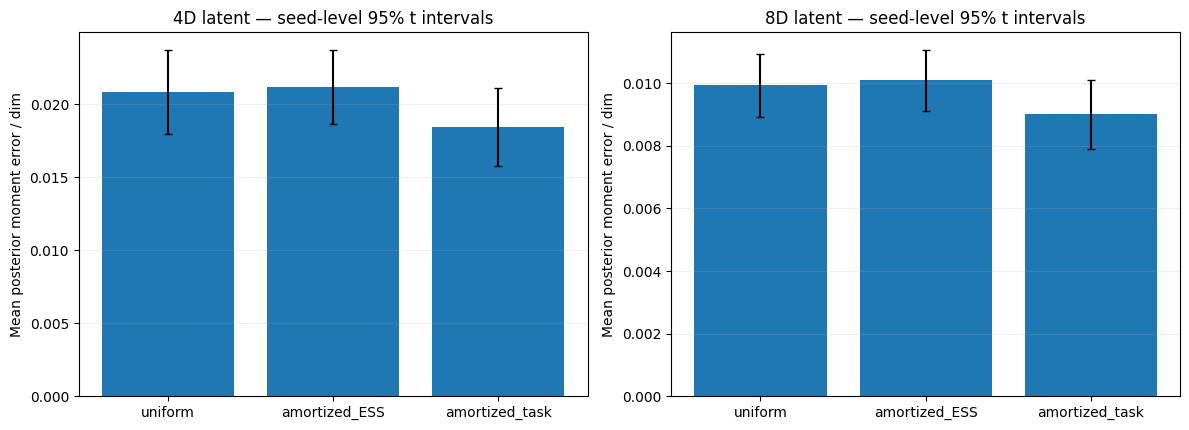

In [22]:

p2_amortized_results, p2_offline_cost, p2_amortized_models = (
    p2_amortized_study(dev_K=DEV_K)
)

p2_amortized_results.to_csv(OUT_DIR/'phase2_amortized_heldout_trials.csv',index=False)
p2_offline_cost.to_csv(OUT_DIR/'phase2_amortized_offline_cost.csv',index=False)
print('\nAmortized task-aware prediction WITHOUT a per-input pilot:')
print(p2_amortized_results.groupby(['dimension','method'])[['per_dim_MSE','abs_logZ_MAE']].mean().round(5))
for metric in ('per_dim_MSE','abs_logZ_MAE'):
    print(p2_ci_paired(p2_amortized_results,'amortized_task',metric=metric).to_string(index=False))

fig,axs=plt.subplots(1,2,figsize=(12,4.4))
for a,d in zip(axs,(4,8)):
    tmp=p2_amortized_results[p2_amortized_results.dimension==d]
    r=tmp.groupby(['method','seed']).per_dim_MSE.mean().reset_index().groupby('method').per_dim_MSE.agg(['mean','std','count'])
    names=['uniform','amortized_ESS','amortized_task']
    a.bar(range(3),[r.loc[t,'mean'] for t in names],yerr=[3.182*r.loc[t,'std']/np.sqrt(r.loc[t,'count']) for t in names],capsize=3)
    a.set(xticks=range(3),xticklabels=names, ylabel='Mean posterior moment error / dim',title=f'{d}D latent — seed-level 95% t intervals')
    a.grid(axis='y',alpha=.2)
fig.tight_layout();fig.savefig(OUT_DIR/'09_amortized_task_aware_no_online_pilot.png',dpi=170);plt.show()

In [23]:

from scipy.stats import t
from itertools import product

def signflip_pvalue(differences, n_mc=100000, seed=2026):
    values = np.asarray(differences, dtype=float)
    n = len(values)
    observed = abs(values.mean())

    if n <= 16:
        # Exact enumeration for smaller experiments
        signs = np.asarray(
            list(product([-1.0, 1.0], repeat=n))
        )
        null_means = np.abs(signs @ values / n)

        return float(np.mean(
            null_means >= observed - 1e-14
        ))

    # Monte Carlo approximation for 25 datasets
    rng = np.random.default_rng(seed)
    signs = rng.choice(
        [-1.0, 1.0],
        size=(n_mc, n)
    )

    null_means = np.abs(signs @ values / n)
    exceed = np.count_nonzero(
        null_means >= observed - 1e-14
    )

    return float((exceed + 1) / (n_mc + 1))


def paired_analysis(df, dimension, method_a,
                    method_b, metric):

    subset = df[df["dimension"] == dimension]

    pivot = subset.pivot(
        index=["seed", "trial"],
        columns="method",
        values=metric
    )

    differences = pivot[method_a] - pivot[method_b]

    # Dataset is the independent experimental unit
    seed_differences = differences.groupby(
        level="seed"
    ).mean()

    values = seed_differences.to_numpy()
    n = len(values)

    mean = values.mean()
    sd = values.std(ddof=1)
    se = sd / np.sqrt(n)

    critical = t.ppf(0.975, df=n-1)

    ci_low = mean - critical * se
    ci_high = mean + critical * se

    p_value = signflip_pvalue(values)

    return {
        "dimension": dimension,
        "metric": metric,
        "comparison": f"{method_a} - {method_b}",
        "n_datasets": n,
        "mean_difference": mean,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "datasets_favor_A": int((values < 0).sum()),
        "signflip_p": p_value
    }


comparisons = [
    ("amortized_task", "uniform"),
    ("amortized_task", "amortized_ESS"),
    ("amortized_ESS", "uniform")
]

metrics = [
    "posterior_mean_MSE",
    "abs_logZ_MAE"
]

analysis_rows = []

for dev_k in [512, 1024, 2048]:

    path = CONFIRM_DIR / f"{dev_k}_trials_new.csv"

    if not path.exists():
        continue

    df = pd.read_csv(path)

    for d in DIMS:
        for metric in metrics:
            for a, b in comparisons:

                result = paired_analysis(
                    df, d, a, b, metric
                )

                result["dev_K"] = dev_k
                analysis_rows.append(result)

analysis = pd.DataFrame(analysis_rows)

analysis = analysis[
    [
        "dev_K", "dimension", "metric",
        "comparison", "n_datasets",
        "mean_difference", "ci_low", "ci_high",
        "datasets_favor_A", "signflip_p"
    ]
]

analysis.to_csv(
    CONFIRM_DIR / "confirmation_statistical_analysis.csv",
    index=False
)

display(analysis.round(6))


,dev_K,dimension,metric,comparison,n_datasets,mean_difference,ci_low,ci_high,datasets_favor_A,signflip_p
0,512,4,posterior_mean_MSE,amortized_task - uniform,25,-0.008938,-0.009609,-0.008266,25,0.000010
1,512,4,posterior_mean_MSE,amortized_task - amortized_ESS,25,-0.011655,-0.012379,-0.010931,25,0.000010
2,512,4,posterior_mean_MSE,amortized_ESS - uniform,25,0.002717,0.002003,0.003432,0,0.000010
3,512,4,abs_logZ_MAE,amortized_task - uniform,25,0.007461,0.005665,0.009257,2,0.000010
4,512,4,abs_logZ_MAE,amortized_task - amortized_ESS,25,0.009202,0.007107,0.011297,1,0.000010
5,512,4,abs_logZ_MAE,amortized_ESS - uniform,25,-0.001742,-0.002803,-0.000680,19,0.002420
6,512,8,posterior_mean_MSE,amortized_task - uniform,25,-0.007127,-0.007610,-0.006643,25,0.000010
7,512,8,posterior_mean_MSE,amortized_task - amortized_ESS,25,-0.008548,-0.009049,-0.008047,25,0.000010
8,512,8,posterior_mean_MSE,amortized_ESS - uniform,25,0.001421,0.000972,0.001870,2,0.000020
9,512,8,abs_logZ_MAE,amortized_task - uniform,25,0.005783,0.003963,0.007603,2,0.000020


In [24]:

import joblib

# Save individual experimental measurements
p2_amortized_results.to_csv(
    OUT_DIR / "amortized_trials.csv",
    index=False
)

# Save offline computational costs
p2_offline_cost.to_csv(
    OUT_DIR / "offline_cost.csv",
    index=False
)

# Save summary statistics
summary = (
    p2_amortized_results
    .groupby(["dimension", "method"], as_index=False)
    .agg(
        posterior_mean_MSE=("per_dim_MSE", "mean"),
        log_evidence_MAE=("abs_logZ_MAE", "mean"),
        trials=("trial", "count")
    )
)

summary.to_csv(
    OUT_DIR / "experiment_summary.csv",
    index=False
)

# Preserve trained allocation predictors
joblib.dump(
    p2_amortized_models,
    OUT_DIR / "allocation_models.joblib"
)

# Record all relevant experimental parameters
config = {
    "experiment": "Amortized Task-Aware Importance Sampling",
    "dev_K": DEV_K,
    "dev_n": 800,
    "dimensions": [4, 8],
    "replicates_per_dataset": 16,
    "online_samples_per_observation": 48,
    "run_id": RUN_ID,
    "output_directory": str(OUT_DIR)
}

with open(OUT_DIR / "experiment_config.json", "w") as f:
    json.dump(config, f, indent=4)

print("\nEXPERIMENT SAVED")
print(summary.to_string(index=False))
print("\nGoogle Drive:", OUT_DIR)



EXPERIMENT SAVED
 dimension         method  posterior_mean_MSE  log_evidence_MAE  trials
         4  amortized_ESS            0.021179          0.292014      64
         4 amortized_task            0.018403          0.300423      64
         4        uniform            0.020831          0.295590      64
         8  amortized_ESS            0.010096          0.331165      64
         8 amortized_task            0.009006          0.339249      64
         8        uniform            0.009934          0.334742      64

Google Drive: /content/drive/MyDrive/Adaptive_VI_Research/dev_K_512/20261119_184240_969906


In [25]:
# ===========================================================
# Budget sweep, independent data splits and conservative CIs
# ===========================================================
def p2_budget_curve(Bs=(24,32,40,44,48,64),data_seeds=P2_DATA_SEEDS,reps=8):
    rows=[]
    for d in (4,8):
        predictor,_=p2_amortized_models[d]
        for seed in data_seeds:
            m=p2_make_model(d,seed,n=P2_TEST_N)
            score=np.exp(predictor.predict(p2_amortized_features(m)))
            for rep in range(reps):
                r=np.random.default_rng(940000+10000*d+100*seed+rep)
                normal=r.normal(size=(len(score),120,d))
                for B in Bs:
                    for meth,ss in [('uniform',np.ones(len(score))),('amortized_task',score)]:
                        xx=p2_eval_amortized(m,ss,meth,normal,rep=f'{seed}-{rep}',B=B)
                        xx['per_observation_B']=B;rows.append(xx)
    return pd.DataFrame(rows)

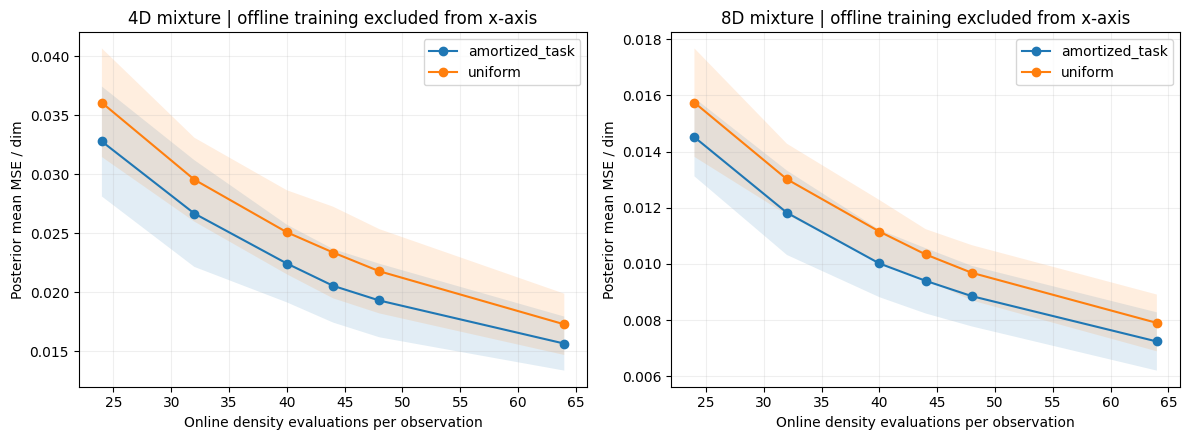

Budget sweep mean MSE:
method                       amortized_task  uniform
dimension per_observation_B                         
4         24                        0.03278  0.03606
          32                        0.02667  0.02954
          40                        0.02243  0.02508
          44                        0.02054  0.02336
          48                        0.01929  0.02177
          64                        0.01564  0.01727
8         24                        0.01451  0.01574
          32                        0.01182  0.01301
          40                        0.01002  0.01115
          44                        0.00940  0.01034
          48                        0.00886  0.00969
          64                        0.00724  0.00790

Clustered confidence intervals by independent data seeds:
 dimension       metric  difference  cluster_CI_low  cluster_CI_high  independent_data_seeds
         4  per_dim_MSE   -0.002428       -0.002619        -0.002196               

In [26]:
p2_budget_results=p2_budget_curve()
p2_budget_results.to_csv(OUT_DIR/'phase2_amortized_budget_curve.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
for i,d in enumerate([4,8]):
    dat=p2_budget_results[p2_budget_results.dimension==d]
    for method,g in dat.groupby('method'):
        val=g.groupby(['seed','per_observation_B']).per_dim_MSE.mean().reset_index().groupby('per_observation_B').per_dim_MSE.agg(['mean','std','count'])
        ax[i].plot(val.index,val['mean'],'o-',label=method)
        ax[i].fill_between(val.index,val['mean']-3.182*val['std']/np.sqrt(val['count']),
                           val['mean']+3.182*val['std']/np.sqrt(val['count']),alpha=.13)
    ax[i].set(xlabel='Online density evaluations per observation',ylabel='Posterior mean MSE / dim',
              title=f'{d}D mixture | offline training excluded from x-axis')
    ax[i].grid(alpha=.2);ax[i].legend()
fig.tight_layout();fig.savefig(OUT_DIR/'10_amortized_budget_sweep.png',dpi=170);plt.show()
print('Budget sweep mean MSE:')
print(p2_budget_results.groupby(['dimension','per_observation_B','method']).per_dim_MSE.mean().unstack().round(5))

# Paired cluster bootstrap samples entire independent data-generation seeds;
# repeats under each seed are NOT treated as independent datasets.
p2_cluster_ci=[]
for d in (4,8):
    for metric in ('per_dim_MSE','abs_logZ_MAE'):
        df=p2_amortized_results[p2_amortized_results.dimension==d]
        pv=df.pivot(index=['seed','trial'],columns='method',values=metric)
        diff=(pv['amortized_task']-pv['uniform']).groupby(level='seed').mean()
        r=np.random.default_rng(7701);draws=r.choice(diff.to_numpy(),(12000,len(diff)),replace=True).mean(axis=1)
        p2_cluster_ci.append({'dimension':d,'metric':metric,'difference':float(diff.mean()),
                  'cluster_CI_low':float(np.quantile(draws,.025)),
                  'cluster_CI_high':float(np.quantile(draws,.975)),
                  'independent_data_seeds':len(diff)})
p2_cluster_ci=pd.DataFrame(p2_cluster_ci)
p2_cluster_ci.to_csv(OUT_DIR/'phase2_amortized_cluster_bootstrap_CIs.csv',index=False)
print('\nClustered confidence intervals by independent data seeds:')
print(p2_cluster_ci.round(6).to_string(index=False))

# ===========================================================
# Does an amortized, NO-PILOT task-aware predictor transfer to a learned VAE?
# All offline teacher computations are counted separately.
# ===========================================================

In [27]:
@torch.no_grad()
def p2_vae_features(net,x):
    mu,ls=net.encode(x)
    reconstruct=net.decode(mu)
    recon_mse=((reconstruct-x)**2).mean(dim=1)
    return np.column_stack([mu.numpy(),ls.numpy(),x.mean(dim=1).numpy(),
                            x.var(dim=1).numpy(),recon_mse.numpy()])


@torch.no_grad()
def p2_vae_offline_teacher(net,train_x,K=1024,batch=32,seed=2022):
    r=np.random.default_rng(seed)
    tau=[];ess=[]
    for start in range(0,len(train_x),batch):
        x=train_x[start:start+batch]
        mu,ls=net.encode(x)
        base=torch.tensor(r.normal(size=(len(x),K,net.latent)),dtype=torch.float32)
        z=mu[:,None,:]+ls.exp()[:,None,:]*base
        lw=p2_vae_logweight(net,x,z,mu,ls).numpy()
        _,tt,_,es=p2_scores(lw,z.numpy(),shrink=0,c=None)
        tau.extend(tt);ess.extend(np.sqrt(np.maximum(0,K/es-1)+.05))
    return np.array(tau),np.array(ess)


@torch.no_grad()
def p2_vae_amortized_trial(net,x,method,scores,normal,reference,model_seed,rep,B=48):
    tic=p2_time.perf_counter()
    mu,ls=net.encode(x);n=len(x)
    counts=capped_allocate(np.asarray(scores),total=n*B,min_k=4,max_k=120)
    ids=np.repeat(np.arange(n),counts)
    js=np.concatenate([np.arange(k) for k in counts])
    it=torch.as_tensor(ids)
    eps=torch.tensor(normal[ids,js],dtype=torch.float32)
    z=mu[it]+torch.exp(ls[it])*eps
    recon=net.decode(z)
    lp=(-.5*((x[it]-recon)/P2_VAE_SIGMA)**2-
        np.log(P2_VAE_SIGMA)-.5*np.log(2*np.pi)).sum(-1)
    lz=(-.5*z**2-.5*np.log(2*np.pi)).sum(-1)
    lq=(-.5*((z-mu[it])/torch.exp(ls[it]))**2-ls[it]-.5*np.log(2*np.pi)).sum(-1)
    weights=(lp+lz-lq).numpy();znp=z.numpy()
    start=np.r_[0,np.cumsum(counts)[:-1]]
    estimated_mean=np.empty((n,net.latent));estZ=np.empty(n)
    for i,(s,k) in enumerate(zip(start,counts)):
        sub=weights[s:s+k];lm=p2_lse(sub)
        estimated_mean[i]=np.exp(sub-lm)@znp[s:s+k]
        estZ[i]=lm-np.log(k)
    return {'model_seed':model_seed,'trial':rep,'method':method,'evals':int(counts.sum()),
            'mean_MSE_vs_ref':float(np.mean((estimated_mean-reference['mean'].numpy())**2)),
            'abs_logZ_error_vs_ref':float(np.mean(np.abs(estZ-reference['logZ'].numpy()))),
            'runtime_seconds':p2_time.perf_counter()-tic}


def p2_run_vae_amortized(reps=12,offline_n=400,teacherK=1024):
    rows=[];offline=[]
    for seed,net,x in p2_models:
        # Each VAE model's training records are the separate offline calibration pool.
        digits=load_digits();allx=digits.data.astype('float32')/16.0
        trainx,_=train_test_split(allx,random_state=2022,test_size=.20,stratify=digits.target)
        rng=np.random.default_rng(seed+100)
        dev=torch.tensor(trainx[rng.choice(len(trainx),offline_n,replace=False)],dtype=torch.float32)
        tt,es=p2_vae_offline_teacher(net,dev,K=teacherK,seed=seed+772)
        fs=p2_vae_features(net,dev)
        regtask=HistGradientBoostingRegressor(max_iter=130,max_leaf_nodes=12,l2_regularization=2.,random_state=seed)
        regess=HistGradientBoostingRegressor(max_iter=130,max_leaf_nodes=12,l2_regularization=2.,random_state=seed)
        regtask.fit(fs,np.log(np.maximum(tt,1e-6)))
        regess.fit(fs,np.log(np.maximum(es,1e-6)))
        offline.append({'model_seed':seed,'teacher_density_evaluations':offline_n*teacherK,'dev_samples':offline_n})
        test_features=p2_vae_features(net,x)
        reference=p2_vae_reference(net,x,Kref=6144,seed=seed+4000)
        predictions={'uniform':np.ones(len(x)),'amortized_task':np.exp(regtask.predict(test_features)),
                     'amortized_ESS':np.exp(regess.predict(test_features))}
        for rep in range(reps):
            r=np.random.default_rng(184000+seed*100+rep)
            normal=r.normal(size=(len(x),120,net.latent)).astype('float32')
            for method,ss in predictions.items():
                rows.append(p2_vae_amortized_trial(net,x,method,ss,normal,reference,seed,rep))
        print('Amortized VAE seed',seed,'done')
    return pd.DataFrame(rows),pd.DataFrame(offline)

Amortized VAE seed 7 done
Amortized VAE seed 19 done
Amortized VAE seed 43 done
Learned VAE: no-pilot amortized allocation, heldout digits:
                mean_MSE_vs_ref  abs_logZ_error_vs_ref
method                                                
amortized_ESS           0.12198                0.37096
amortized_task          0.12088                0.37146
uniform                 0.12216                0.36030
               metric  paired_delta   CI_low  CI_high  independent_training_seeds
      mean_MSE_vs_ref      -0.00128 -0.00439  0.00283                           3
abs_logZ_error_vs_ref       0.01116  0.00126  0.01986                           3


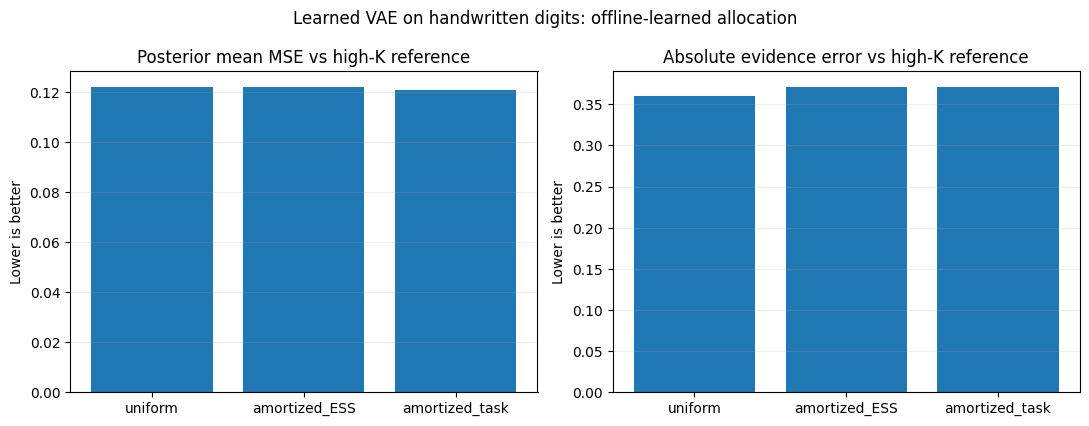

Python allocator memory (NOT total PyTorch/CPU peak):         policy  dimension  python_tracemalloc_peak_MB  example_runtime_seconds  total_density_evals
amortized_task          8                     2.37793                  0.08041                 4032


In [28]:
p2_vae_amortized,p2_vae_amortized_cost=p2_run_vae_amortized()
p2_vae_amortized.to_csv(OUT_DIR/'phase2_vae_amortized_heldout.csv',index=False)
p2_vae_amortized_cost.to_csv(OUT_DIR/'phase2_vae_amortized_offline_cost.csv',index=False)
print('Learned VAE: no-pilot amortized allocation, heldout digits:')
print(p2_vae_amortized.groupby('method')[['mean_MSE_vs_ref','abs_logZ_error_vs_ref']].mean().round(5))

def p2_vae_amortized_ci(df, metric):
    pv=df.pivot(index=['model_seed','trial'],columns='method',values=metric)
    delta=(pv['amortized_task']-pv['uniform']).groupby(level='model_seed').mean().to_numpy()
    draw=np.random.default_rng(9932).choice(delta,(10000,len(delta)),replace=True).mean(axis=1)
    return {'metric':metric,'paired_delta':float(delta.mean()),
        'CI_low':float(np.quantile(draw,.025)),'CI_high':float(np.quantile(draw,.975)),
        'independent_training_seeds':len(delta)}
p2_am_vae_ci=pd.DataFrame([p2_vae_amortized_ci(p2_vae_amortized,metric)
    for metric in ('mean_MSE_vs_ref','abs_logZ_error_vs_ref')])
p2_am_vae_ci.to_csv(OUT_DIR/'phase2_vae_amortized_seed_CIs.csv',index=False)
print(p2_am_vae_ci.round(5).to_string(index=False))

fig,ax=plt.subplots(1,2,figsize=(11,4.3))
methods=['uniform','amortized_ESS','amortized_task']
for a,metric,title in zip(ax,['mean_MSE_vs_ref','abs_logZ_error_vs_ref'],
                           ['Posterior mean MSE vs high-K reference','Absolute evidence error vs high-K reference']):
    means=p2_vae_amortized.groupby('method')[metric].mean()
    a.bar(range(3),[means[k] for k in methods])
    a.set(xticks=range(3),xticklabels=methods,ylabel='Lower is better',title=title)
    a.grid(axis='y',alpha=.2)
fig.suptitle('Learned VAE on handwritten digits: offline-learned allocation')
fig.tight_layout();fig.savefig(OUT_DIR/'11_amortized_learned_vae.png',dpi=170);plt.show()

# A narrow, reproducible memory benchmark in Python-space, separate from true CPU/GPU peaks.
p2_tracemalloc.start()
_demo=p2_make_model(8,seed=500,n=P2_TEST_N)
_demo_norm=np.random.default_rng(507).normal(size=(P2_TEST_N,120,8))
_demo_score=np.exp(p2_amortized_models[8][0].predict(p2_amortized_features(_demo)))
_demo_t0=p2_time.perf_counter()
_demo_out=p2_eval_amortized(_demo,_demo_score,'amortized_task',_demo_norm,rep='benchmark')
_p2_time=p2_time.perf_counter()-_demo_t0
current,peak=p2_tracemalloc.get_traced_memory();p2_tracemalloc.stop()
p2_mem=pd.DataFrame([{'policy':'amortized_task','dimension':8,'python_tracemalloc_peak_MB':peak/1e6,
                      'example_runtime_seconds':_p2_time,'total_density_evals':P2_TEST_N*48}])
p2_mem.to_csv(OUT_DIR/'phase2_python_memory_profile.csv',index=False)
print('Python allocator memory (NOT total PyTorch/CPU peak):',p2_mem.round(5).to_string(index=False))

In [29]:
# Additional mathematical verification and real-data quality diagnostics.
def p2_exact_posterior_proposal_KL(m,draws=800,seed=992):
    rng=np.random.default_rng(seed);x=m['x'];n,d=x.shape
    logZ,truemu=p2_truth(m)
    lp=np.stack([p2_lpdiag(x,m['means'][j],np.sqrt(1+m['sigma'][:,None]**2))+
                  np.log(m['prior_mix'][j]) for j in range(2)],axis=1)
    gam=np.exp(lp-p2_lse(lp,axis=1,keepdims=True))
    choices=(rng.random((n,draws))>gam[:,0,None]).astype(int)
    sig2=m['sigma'][:,None,None]**2
    mu=(x[:,None,:]+sig2*m['means'][choices])/(1+sig2)
    z=mu+rng.normal(size=(n,draws,d))*np.sqrt(sig2/(1+sig2))
    # Log posterior = log joint - exact log evidence, evaluating under true mixture.
    lpz=np.stack([p2_lpdiag(z,m['means'][j],np.ones(d))+np.log(m['prior_mix'][j]) for j in range(2)],axis=-1)
    logpost=p2_lse(lpz,axis=-1)+p2_lpdiag(x[:,None,:],z,m['sigma'][:,None,None])-logZ[:,None]
    qm,qs=p2_q_params(m)
    logq=p2_lpdiag(z,qm[:,None,:],qs[:,None,:])
    differences=logpost-logq
    return {'dimension':d,'KL_posterior_to_q_MC':float(differences.mean()),
            'MC_standard_error_conditioned_inputs':float(differences.mean(axis=1).std(ddof=1)/np.sqrt(n)),
            'samples_per_input':draws,'observations':n}

p2_proposal_KL=pd.DataFrame([p2_exact_posterior_proposal_KL(p2_make_model(d,seed=99,n=120),seed=900+d)
                              for d in (4,8)])
p2_proposal_KL.to_csv(OUT_DIR/'phase2_analytic_posterior_vs_proposal_KL.csv',index=False)
print('Heldout true-posterior KL(p||q) on synthetic mixtures; DOES NOT change with allocation:')
print(p2_proposal_KL.round(5).to_string(index=False))

p2_real_quality=[]
for seed,net,x in p2_models:
    with torch.no_grad():
        mu,ls=net.encode(x)
        reconstruction=net.decode(mu)
        ref=p2_vae_reference(net,x,seed=seed+4000,Kref=6144)
        p2_real_quality.append({'model_seed':seed,
              'heldout_reconstruction_MSE':float(torch.mean((reconstruction-x)**2)),
              'heldout_estimated_log_marginal':float(ref['logZ'].mean()),
              'median_reference_ESS':float(torch.median(ref['ESS'])),
              'reference_samples_per_observation':6144})
p2_real_quality=pd.DataFrame(p2_real_quality)
p2_real_quality.to_csv(OUT_DIR/'phase2_learned_VAE_heldout_density_metrics.csv',index=False)
print('Learned VAE heldout metrics:')
print(p2_real_quality.round(5).to_string(index=False))

# A budget accounting sensitivity number, not a demonstrated production speedup.
required_obs=int(np.ceil((800*2048)/(48-44)))
print(f'At 4 hypothetical online evaluations saved per input, an offline teacher budget of 800*2048'
      f' evaluations would only break even after {required_obs:,} evaluated inputs, before other costs.')
print('No claim of globally optimal or novel allocation is made; known Neyman allocation and adaptive IS precede this work.')

Heldout true-posterior KL(p||q) on synthetic mixtures; DOES NOT change with allocation:
 dimension  KL_posterior_to_q_MC  MC_standard_error_conditioned_inputs  samples_per_input  observations
         4               1.25856                               0.03231                800           120
         8               1.41824                               0.03391                800           120
Learned VAE heldout metrics:
 model_seed  heldout_reconstruction_MSE  heldout_estimated_log_marginal  median_reference_ESS  reference_samples_per_observation
          7                     0.05570                        -1.85291             312.59488                               6144
         19                     0.05738                        -2.73419             213.38396                               6144
         43                     0.06336                        -4.67880             237.93805                               6144
At 4 hypothetical online evaluations saved per input, a